# Construcción de variables y primeros modelos predictivos

El primer notebook permitió conocer la estructura del problema y dejó preparadas las tablas que utilizaremos para el modelado. El análisis exploratorio mostró, entre otros aspectos, una marcada componente temporal en las ventas, diferencias importantes entre tiendas y departamentos y la existencia de algunos huecos en determinadas series. A partir de estas observaciones, en este segundo notebook comenzamos la construcción de variables y los primeros experimentos predictivos.

El planteamiento inicial es **predecir directamente las ventas semanales (`Weekly_Sales`)** a partir de la información disponible. Para ello realizamos primero una partición temporal de los datos y construimos distintas variables explicativas, incorporando tanto información temporal como características de las tiendas, promociones y variables económicas.

Una parte especialmente importante del notebook será la incorporación de información sobre el propio histórico de ventas. Dada la estacionalidad observada, estudiaremos las ventas registradas por cada tienda y departamento 52 semanas antes mediante `Lag_52`. Esta variable permitirá no solo enriquecer los primeros modelos de predicción directa, sino también construir una referencia estacional sencilla con la que comparar su rendimiento.

Los resultados de estos primeros experimentos nos llevarán posteriormente a **replantear el objetivo de predicción**. En lugar de intentar estimar directamente el nivel completo de ventas, estudiaremos si resulta más conveniente partir de la referencia proporcionada por `Lag_52` y modelar únicamente la diferencia respecto al año anterior. Definiremos así un residuo interanual y reconstruiremos posteriormente la predicción final de ventas sumando el residuo estimado a la referencia anual.

Por tanto, el notebook recoge una evolución del planteamiento: desde la predicción directa de `Weekly_Sales` hasta la formulación de un problema de aprendizaje residual. Se mantienen también los experimentos que no produjeron una mejora, ya que son los que justifican las decisiones tomadas y permiten entender por qué el problema acaba formulándose de esta manera.

## 1. Entorno y carga de los datos procesados

Partimos de `train_processed.parquet` y `test_processed.parquet`, exportados por el primer notebook en Google Drive. Se mantiene el entorno de Google Colab.

Revisamos los tipos y reducimos el uso de memoria. La conversión de variables continuas a `float32` conserva el planteamiento original, aunque puede introducir pequeñas diferencias de redondeo respecto a `float64`. Las comprobaciones posteriores permiten confirmar las dimensiones, las fechas y los valores ausentes que recibimos de la preparación anterior.

In [1]:
# =============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS
# =============================================================================

import os
import numpy as np
import pandas as pd

from google.colab import drive

# Configuración de visualización de pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
# =============================================================================
# CONTROL GLOBAL DE ENTRENAMIENTO Y ACTUALIZACIÓN DE ARTEFACTOS
# =============================================================================
# TRAIN=True: reentrenar las tres regresiones, sobrescribir sus artefactos
#             y exportar de nuevo los datasets del notebook neuronal.
# TRAIN=False: cargar modelos compatibles; si faltan o cambian los datos
#              de entrenamiento/configuración, reentrenar automáticamente.
#              Conservar los datasets exportados si su origen es el mismo.
TRAIN = True
print(f"Modo de entrenamiento y exportación: TRAIN = {TRAIN}")


Modo de entrenamiento y exportación: TRAIN = True


In [3]:
# =============================================================================
# 2. CARGA DE LOS DATASETS PROCESADOS
# =============================================================================

# Montamos Google Drive
drive.mount("/content/drive")

# Ruta donde se encuentran los datasets procesados
DATA_PATH = "/content/drive/MyDrive/TFM/data/processed"

# Cargamos los datasets
train_processed = pd.read_parquet(
    os.path.join(DATA_PATH, "train_processed.parquet")
)

test_processed = pd.read_parquet(
    os.path.join(DATA_PATH, "test_processed.parquet")
)

# Comprobamos dimensiones
print("Train:", train_processed.shape)
print("Test: ", test_processed.shape)

display(train_processed.head())

Mounted at /content/drive
Train: (421570, 21)
Test:  (115064, 20)


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,MarkDown1_isna,MarkDown2_isna,MarkDown3_isna,MarkDown4_isna,MarkDown5_isna,Type,Size
0,1,1,2010-02-05,"24,924.50",False,42.31,2.57,0.00,0.00,0.00,0.00,0.00,211.10,8.11,True,True,True,True,True,A,151315
1,1,1,2010-02-12,"46,039.49",True,38.51,2.55,0.00,0.00,0.00,0.00,0.00,211.24,8.11,True,True,True,True,True,A,151315
2,1,1,2010-02-19,"41,595.55",False,39.93,2.51,0.00,0.00,0.00,0.00,0.00,211.29,8.11,True,True,True,True,True,A,151315
3,1,1,2010-02-26,"19,403.54",False,46.63,2.56,0.00,0.00,0.00,0.00,0.00,211.32,8.11,True,True,True,True,True,A,151315
4,1,1,2010-03-05,"21,827.90",False,46.50,2.62,0.00,0.00,0.00,0.00,0.00,211.35,8.11,True,True,True,True,True,A,151315


In [4]:
# =============================================================================
# FIRMAS DE DATOS Y GESTIÓN DE MODELOS LINEALES
# =============================================================================
import hashlib
import json
from pathlib import Path
import joblib

LINEAR_MODEL_DIR = Path('/content/drive/MyDrive/TFM/models/linear_baselines')
LINEAR_MODEL_DIR.mkdir(parents=True, exist_ok=True)


def firma_datos_modelo(X, y, config):
    """Invalida el modelo cuando cambian filas, columnas, targets o ajustes."""
    digest = hashlib.sha256(json.dumps(config, sort_keys=True, default=str).encode())
    for nombre, frame in [('X', X), ('y', y)]:
        if isinstance(frame, pd.Series):
            frame = frame.to_frame()
        digest.update(nombre.encode())
        digest.update(str(frame.shape).encode())
        digest.update('|'.join(map(str, frame.columns)).encode())
        digest.update('|'.join(map(str, frame.dtypes)).encode())
        digest.update(pd.util.hash_pandas_object(frame, index=True).to_numpy().tobytes())
    return digest.hexdigest()


def obtener_modelo_lineal(nombre, modelo_nuevo, X, y, config):
    """Cargar si todo coincide; en otro caso, ajustar y sobrescribir."""
    ruta = LINEAR_MODEL_DIR / f'{nombre}.joblib'
    ruta_firma = LINEAR_MODEL_DIR / f'{nombre}.signature.json'
    firma = firma_datos_modelo(X, y, config)
    motivo = None
    if TRAIN:
        motivo = 'TRAIN=True'
    elif not ruta.exists() or not ruta_firma.exists():
        motivo = 'faltan modelo o metadatos de compatibilidad'
    else:
        try:
            guardada = json.loads(ruta_firma.read_text(encoding='utf-8'))
            if guardada.get('signature') != firma:
                motivo = 'cambiaron los datos de entrenamiento o la configuración'
        except (OSError, ValueError):
            motivo = 'metadatos de compatibilidad ilegibles'

    if motivo is None:
        try:
            modelo = joblib.load(ruta)
            print(f'✓ {nombre}: modelo compatible cargado.')
            return modelo
        except Exception as exc:
            motivo = f'falló la carga: {type(exc).__name__}: {exc}'

    print(f'↻ {nombre}: entrenando ({motivo}).')
    modelo_nuevo.fit(X, y)
    joblib.dump(modelo_nuevo, ruta)
    ruta_firma.write_text(json.dumps({'signature': firma,
                                     'config': config}, indent=2,
                                    default=str), encoding='utf-8')
    print(f'✓ {nombre}: modelo y firma guardados (sobrescribiendo si existían).')
    return modelo_nuevo


In [5]:
# =============================================================================
# 3. TIPOS DE DATOS ANTES DE LA OPTIMIZACIÓN
# =============================================================================

print("TRAIN")
display(train_processed.dtypes.to_frame("dtype"))

print("\nTEST")
display(test_processed.dtypes.to_frame("dtype"))

TRAIN


,dtype
Store,int64
Dept,int64
Date,datetime64[ns]
Weekly_Sales,float64
IsHoliday,bool
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64



TEST


,dtype
Store,int64
Dept,int64
Date,datetime64[ns]
IsHoliday,bool
Temperature,float64
Fuel_Price,float64
MarkDown1,float64
MarkDown2,float64
MarkDown3,float64
MarkDown4,float64


In [6]:
# =============================================================================
# 4. OPTIMIZACIÓN DE TIPOS DE DATOS
# =============================================================================

def optimize_dtypes(df):
    """
    Reduce el uso de memoria mediante tipos más compactos.
    La conversión a float32 puede introducir diferencias de redondeo.
    """

    df = df.copy()

    # -------------------------------------------------------------------------
    # Variables enteras
    # -------------------------------------------------------------------------

    # Store y Dept pueden almacenarse como int8
    for col in ["Store", "Dept"]:
        if col in df.columns:

            # Comprobamos que los valores caben en int8 antes de convertir
            assert df[col].min() >= np.iinfo(np.int8).min
            assert df[col].max() <= np.iinfo(np.int8).max

            df[col] = df[col].astype(np.int8)

    # Size requiere un rango mayor
    if "Size" in df.columns:

        assert df["Size"].min() >= np.iinfo(np.int32).min
        assert df["Size"].max() <= np.iinfo(np.int32).max

        df["Size"] = df["Size"].astype(np.int32)

    # -------------------------------------------------------------------------
    # Variables continuas
    # -------------------------------------------------------------------------

    float32_cols = [
        "Weekly_Sales",
        "Temperature",
        "Fuel_Price",
        "MarkDown1",
        "MarkDown2",
        "MarkDown3",
        "MarkDown4",
        "MarkDown5",
        "CPI",
        "Unemployment"
    ]

    for col in float32_cols:
        if col in df.columns:
            df[col] = df[col].astype(np.float32)

    # -------------------------------------------------------------------------
    # Variables booleanas
    # -------------------------------------------------------------------------

    bool_cols = [
        "IsHoliday",
        "MarkDown1_isna",
        "MarkDown2_isna",
        "MarkDown3_isna",
        "MarkDown4_isna",
        "MarkDown5_isna"
    ]

    for col in bool_cols:
        if col in df.columns:
            df[col] = df[col].astype(bool)

    # -------------------------------------------------------------------------
    # Variable temporal
    # -------------------------------------------------------------------------

    if "Date" in df.columns:
        df["Date"] = pd.to_datetime(df["Date"])

    # -------------------------------------------------------------------------
    # Variable categórica
    # -------------------------------------------------------------------------

    if "Type" in df.columns:
        df["Type"] = df["Type"].astype("category")

    return df


train_processed = optimize_dtypes(train_processed)
test_processed = optimize_dtypes(test_processed)

In [7]:
# =============================================================================
# 5. COMPROBACIÓN DE LOS TIPOS OPTIMIZADOS
# =============================================================================

print("TRAIN")
display(train_processed.dtypes.to_frame("dtype"))

print("\nTEST")
display(test_processed.dtypes.to_frame("dtype"))

print("\nMemoria utilizada:")
print(
    f"Train: "
    f"{train_processed.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)
print(
    f"Test:  "
    f"{test_processed.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)

TRAIN


,dtype
Store,int8
Dept,int8
Date,datetime64[ns]
Weekly_Sales,float32
IsHoliday,bool
Temperature,float32
Fuel_Price,float32
MarkDown1,float32
MarkDown2,float32
MarkDown3,float32



TEST


,dtype
Store,int8
Dept,int8
Date,datetime64[ns]
IsHoliday,bool
Temperature,float32
Fuel_Price,float32
MarkDown1,float32
MarkDown2,float32
MarkDown3,float32
MarkDown4,float32



Memoria utilizada:
Train: 24.52 MB
Test:  6.26 MB


In [8]:
# =============================================================================
# 6. COMPROBACIONES BÁSICAS
# =============================================================================

print("Valores nulos:")
print(f"Train: {train_processed.isna().sum().sum()}")
print(f"Test:  {test_processed.isna().sum().sum()}")

print("\nFilas duplicadas:")
print(f"Train: {train_processed.duplicated().sum()}")
print(f"Test:  {test_processed.duplicated().sum()}")

print("\nRango temporal:")
print(
    f"Train: {train_processed['Date'].min().date()} "
    f"→ {train_processed['Date'].max().date()}"
)
print(
    f"Test:  {test_processed['Date'].min().date()} "
    f"→ {test_processed['Date'].max().date()}"
)

print("\nWeekly_Sales:")
print("En train:", "Weekly_Sales" in train_processed.columns)
print("En test: ", "Weekly_Sales" in test_processed.columns)

Valores nulos:
Train: 0
Test:  76324

Filas duplicadas:
Train: 0
Test:  0

Rango temporal:
Train: 2010-02-05 → 2012-10-26
Test:  2012-11-02 → 2013-07-26

Weekly_Sales:
En train: True
En test:  False


In [9]:
# =============================================================================
# 7. LOCALIZACIÓN DE VALORES NULOS EN TEST
# =============================================================================

nulls_test = (
    test_processed
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

display(
    nulls_test.to_frame("Missing_Count")
    .assign(
        Missing_Percentage=lambda x:
        100 * x["Missing_Count"] / len(test_processed)
    )
)

,Missing_Count,Missing_Percentage
CPI,38162,33.17
Unemployment,38162,33.17


## 2. Construcción de variables de calendario

Vamos a crear primero las variables que dependen únicamente de `Date`: año, mes, semana del año, índice temporal y codificación cíclica. No utilizan ventas futuras y pueden calcularse también para las fechas de test.

`TimeIndex` cuenta las semanas desde el inicio del histórico, con una misma fecha de origen para ambos conjuntos. En el primer modelo utilizaremos este índice junto con `WeekSin` y `WeekCos`; `Year`, `Month` y `WeekOfYear` se conservan en las tablas, pero no se incluyen como entradas adicionales de esa regresión.

### 2.1. Codificación cíclica de la semana del año

La variable `WeekOfYear` toma valores enteros entre 1 y 52/53 para representar la semana del año. Sin embargo, utilizar directamente este valor puede introducir una representación inadecuada de la temporalidad, ya que el modelo interpretaría que la semana 52 está muy alejada de la semana 1, cuando en realidad ambas son semanas consecutivas.

Para evitar este problema, se utiliza una codificación cíclica mediante funciones seno y coseno:

$$
\text{WeekSin} = \sin\left(\frac{2\pi \cdot \text{WeekOfYear}}{52}\right)
$$

$$
\text{WeekCos} = \cos\left(\frac{2\pi \cdot \text{WeekOfYear}}{52}\right)
$$

Esta transformación proyecta las semanas del año sobre una circunferencia, de forma que las semanas cercanas temporalmente también quedan próximas en la representación numérica. Así, por ejemplo, la semana 52 y la semana 1 presentan valores similares, reflejando correctamente la naturaleza periódica del calendario.

Se mantiene un periodo de 52 semanas como aproximación al ciclo anual. Si aparece una semana ISO 53, su codificación coincide con la de la semana 1; por tanto, esta representación no distingue todos los casos del calendario. La combinación de seno y coseno permite representar la posición dentro del ciclo sin imponer una tendencia lineal entre las semanas.

In [10]:
# =============================================================================
# 8. CREACIÓN DE VARIABLES TEMPORALES
# =============================================================================

# Fecha inicial del histórico.
# Se utiliza como referencia común para train y test.
DATE_ORIGIN = train_processed["Date"].min()


def create_time_features(df, date_origin):
    """
    Crea variables temporales a partir de Date sin utilizar
    información de Weekly_Sales.
    """

    df = df.copy()

    # Año
    df["Year"] = df["Date"].dt.year.astype(np.int16)

    # Mes
    df["Month"] = df["Date"].dt.month.astype(np.int8)

    # Semana del año (1-52/53)
    df["WeekOfYear"] = (
        df["Date"]
        .dt.isocalendar()
        .week
        .astype(np.int8)
    )

    # Índice temporal expresado en semanas desde el inicio del histórico
    df["TimeIndex"] = (
        (df["Date"] - date_origin).dt.days // 7
    ).astype(np.int16)

    # -------------------------------------------------------------------------
    # Codificación cíclica de la semana del año
    # -------------------------------------------------------------------------
    # Evita que el modelo interprete, por ejemplo, que la semana 52
    # está muy alejada de la semana 1.

    df["WeekSin"] = np.sin(
        2 * np.pi * df["WeekOfYear"] / 52
    ).astype(np.float32)

    df["WeekCos"] = np.cos(
        2 * np.pi * df["WeekOfYear"] / 52
    ).astype(np.float32)

    return df


train_model = create_time_features(
    train_processed,
    DATE_ORIGIN
)

test_model = create_time_features(
    test_processed,
    DATE_ORIGIN
)

In [11]:
# =============================================================================
# 9. COMPROBACIÓN DE VARIABLES TEMPORALES
# =============================================================================

time_cols = [
    "Date",
    "Year",
    "Month",
    "WeekOfYear",
    "TimeIndex",
    "WeekSin",
    "WeekCos"
]

print("TRAIN")
display(train_model[time_cols].head())

print("\nÚltimas semanas de TRAIN")
display(train_model[time_cols].tail())

print("\nPrimeras semanas de TEST")
display(test_model[time_cols].head())

TRAIN


,Date,Year,Month,WeekOfYear,TimeIndex,WeekSin,WeekCos
0,2010-02-05,2010,2,5,0,0.57,0.82
1,2010-02-12,2010,2,6,1,0.66,0.75
2,2010-02-19,2010,2,7,2,0.75,0.66
3,2010-02-26,2010,2,8,3,0.82,0.57
4,2010-03-05,2010,3,9,4,0.89,0.46



Últimas semanas de TRAIN


,Date,Year,Month,WeekOfYear,TimeIndex,WeekSin,WeekCos
421565,2012-09-28,2012,9,39,138,-1.00,-0.00
421566,2012-10-05,2012,10,40,139,-0.99,0.12
421567,2012-10-12,2012,10,41,140,-0.97,0.24
421568,2012-10-19,2012,10,42,141,-0.94,0.35
421569,2012-10-26,2012,10,43,142,-0.89,0.46



Primeras semanas de TEST


,Date,Year,Month,WeekOfYear,TimeIndex,WeekSin,WeekCos
0,2012-11-02,2012,11,44,143,-0.82,0.57
1,2012-11-09,2012,11,45,144,-0.75,0.66
2,2012-11-16,2012,11,46,145,-0.66,0.75
3,2012-11-23,2012,11,47,146,-0.57,0.82
4,2012-11-30,2012,11,48,147,-0.46,0.89


In [12]:
# =============================================================================
# 10. VALIDACIÓN DE VARIABLES TEMPORALES
# =============================================================================

print("Rango de Year:")
print(
    "Train:",
    train_model["Year"].min(),
    "→",
    train_model["Year"].max()
)
print(
    "Test: ",
    test_model["Year"].min(),
    "→",
    test_model["Year"].max()
)

print("\nRango de WeekOfYear:")
print(
    "Train:",
    train_model["WeekOfYear"].min(),
    "→",
    train_model["WeekOfYear"].max()
)
print(
    "Test: ",
    test_model["WeekOfYear"].min(),
    "→",
    test_model["WeekOfYear"].max()
)

print("\nRango de TimeIndex:")
print(
    "Train:",
    train_model["TimeIndex"].min(),
    "→",
    train_model["TimeIndex"].max()
)
print(
    "Test: ",
    test_model["TimeIndex"].min(),
    "→",
    test_model["TimeIndex"].max()
)

print("\nNulos generados:")
print(
    train_model[
        ["Year", "Month", "WeekOfYear",
         "TimeIndex", "WeekSin", "WeekCos"]
    ].isna().sum()
)

Rango de Year:
Train: 2010 → 2012
Test:  2012 → 2013

Rango de WeekOfYear:
Train: 1 → 52
Test:  1 → 52

Rango de TimeIndex:
Train: 0 → 142
Test:  143 → 181

Nulos generados:
Year          0
Month         0
WeekOfYear    0
TimeIndex     0
WeekSin       0
WeekCos       0
dtype: int64


## 3. Partición temporal de entrenamiento y validación

La competición de Kaggle proporciona los datos ya divididos en dos conjuntos. El primero (`train`) contiene el histórico de ventas junto con la variable objetivo `Weekly_Sales`, mientras que el segundo (`test`) corresponde a las 39 semanas posteriores y no incluye dicha variable, ya que el objetivo de la competición es predecir esas ventas.

Esta estructura impide evaluar directamente el rendimiento de los modelos sobre el conjunto de test, por lo que es necesario reservar una parte del histórico para realizar la validación. Dado que se trata de un problema de predicción temporal, la validación debe contener fechas posteriores a las utilizadas para el entrenamiento; una partición aleatoria mezclaría ambos periodos y produciría una evaluación poco representativa del escenario real.

Para mantener un horizonte temporal comparable al del test, se reservan las últimas 39 semanas del histórico como conjunto de validación:

| Conjunto | Periodo | Semanas | Observaciones |
| --- | --- | ---: | ---: |
| Entrenamiento interno | 05/02/2010–27/01/2012 | 104 | 305.982 |
| Validación | 03/02/2012–26/10/2012 | 39 | 115.588 |
| Test | 02/11/2012–26/07/2013 | 39 | 115.064 |

A partir de este punto, **entrenamiento interno** hace referencia al subconjunto utilizado para ajustar los modelos, mientras que **histórico completo** engloba tanto el entrenamiento interno como las observaciones reservadas para validación. Todas las métricas obtenidas en este notebook se calcularán sobre el conjunto de validación, ya que el conjunto de test no dispone de los valores reales de `Weekly_Sales`.

No obstante, esta estrategia presenta una limitación importante derivada del propio diseño de la competición. Aunque validación y test tienen la misma duración, no abarcan las mismas fechas del calendario. En particular, el conjunto de validación finaliza antes de campañas comerciales tan relevantes como **Thanksgiving** y **Christmas**, mientras que estas sí están presentes en el conjunto de test. Como consecuencia, durante el desarrollo no es posible evaluar el comportamiento de los modelos en algunos de los periodos de mayor impacto sobre las ventas.

Este aspecto puede considerarse una limitación del planteamiento de la competición, ya que obliga a seleccionar el modelo sin disponer de métricas sobre algunas de las semanas más críticas del horizonte final de predicción. Aun así, la partición temporal elegida sigue siendo la alternativa más coherente para evitar fuga de información (*data leakage*) y aproximar, en la medida de lo posible, el escenario real de predicción.

Además de verificar las fechas de cada partición, también se comprobarán las combinaciones **tienda-departamento** y la longitud de sus series temporales. Estas comprobaciones serán especialmente relevantes en los siguientes apartados, donde se construirán variables retardadas (*lags*), ya que un retardo solo puede calcularse si la observación histórica correspondiente existe y pertenece a un instante anterior al periodo que se desea predecir.

In [13]:
# =============================================================================
# 11. DIVISIÓN TEMPORAL TRAIN / VALIDATION
# =============================================================================

# Últimas 39 semanas del histórico para validación
N_VALID_WEEKS = 39

# Fechas únicas ordenadas
unique_dates = np.sort(train_model["Date"].unique())

# Fecha de inicio del periodo de validación
validation_start_date = pd.Timestamp(unique_dates[-N_VALID_WEEKS])

print("Inicio de validación:", validation_start_date.date())

# División temporal
train_internal = train_model[
    train_model["Date"] < validation_start_date
].copy()

validation = train_model[
    train_model["Date"] >= validation_start_date
].copy()

# Ordenamos por tiempo y por serie
train_internal = train_internal.sort_values(
    ["Store", "Dept", "Date"]
).reset_index(drop=True)

validation = validation.sort_values(
    ["Store", "Dept", "Date"]
).reset_index(drop=True)

Inicio de validación: 2012-02-03


In [14]:
# =============================================================================
# 12. COMPROBACIÓN DEL SPLIT TEMPORAL
# =============================================================================

print("TRAIN INTERNO")
print("Filas:", len(train_internal))
print(
    "Rango:",
    train_internal["Date"].min().date(),
    "→",
    train_internal["Date"].max().date()
)
print(
    "Semanas:",
    train_internal["Date"].nunique()
)

print("\nVALIDACIÓN")
print("Filas:", len(validation))
print(
    "Rango:",
    validation["Date"].min().date(),
    "→",
    validation["Date"].max().date()
)
print(
    "Semanas:",
    validation["Date"].nunique()
)

print("\nTEST REAL")
print("Filas:", len(test_model))
print(
    "Rango:",
    test_model["Date"].min().date(),
    "→",
    test_model["Date"].max().date()
)
print(
    "Semanas:",
    test_model["Date"].nunique()
)

TRAIN INTERNO
Filas: 305982
Rango: 2010-02-05 → 2012-01-27
Semanas: 104

VALIDACIÓN
Filas: 115588
Rango: 2012-02-03 → 2012-10-26
Semanas: 39

TEST REAL
Filas: 115064
Rango: 2012-11-02 → 2013-07-26
Semanas: 39


In [15]:
# =============================================================================
# 13. COMPROBACIÓN DE AUSENCIA DE SOLAPAMIENTO TEMPORAL
# =============================================================================

assert train_internal["Date"].max() < validation["Date"].min()

print("✓ No existe solapamiento temporal entre train y validación.")

✓ No existe solapamiento temporal entre train y validación.


In [16]:
# =============================================================================
# 14. COMPROBACIÓN DE SERIES STORE-DEPT
# =============================================================================

train_pairs = set(
    train_internal[["Store", "Dept"]]
    .itertuples(index=False, name=None)
)

validation_pairs = set(
    validation[["Store", "Dept"]]
    .itertuples(index=False, name=None)
)

test_pairs = set(
    test_model[["Store", "Dept"]]
    .itertuples(index=False, name=None)
)

# Pares presentes en validación pero no en entrenamiento
new_validation_pairs = validation_pairs - train_pairs

# Pares presentes en test pero no en todo el histórico
full_train_pairs = set(
    train_model[["Store", "Dept"]]
    .itertuples(index=False, name=None)
)

new_test_pairs = test_pairs - full_train_pairs

print("Pares Store-Dept en train interno:", len(train_pairs))
print("Pares Store-Dept en validación:", len(validation_pairs))
print("Pares Store-Dept en test:", len(test_pairs))

print(
    "\nPares nuevos en validación:",
    len(new_validation_pairs)
)

print(
    "Pares nuevos en test:",
    len(new_test_pairs)
)

Pares Store-Dept en train interno: 3306
Pares Store-Dept en validación: 3204
Pares Store-Dept en test: 3169

Pares nuevos en validación: 25
Pares nuevos en test: 11


In [17]:
# =============================================================================
# 15. INSPECCIÓN DE SERIES NUEVAS
# =============================================================================

if len(new_validation_pairs) > 0:
    print("Pares presentes en validación pero no en train:")

    display(
        pd.DataFrame(
            sorted(new_validation_pairs),
            columns=["Store", "Dept"]
        )
    )
else:
    print(
        "✓ Todos los pares Store-Dept de validación "
        "ya aparecen en entrenamiento."
    )


if len(new_test_pairs) > 0:
    print("\nPares presentes en test pero no en el histórico:")

    display(
        pd.DataFrame(
            sorted(new_test_pairs),
            columns=["Store", "Dept"]
        )
    )
else:
    print(
        "\n✓ Todos los pares Store-Dept del test "
        "ya aparecen en el histórico."
    )

Pares presentes en validación pero no en train:


,Store,Dept
0,3,83
1,7,99
2,12,99
3,15,99
4,16,99
5,17,99
6,19,39
7,21,50
8,21,99
9,23,99



Pares presentes en test pero no en el histórico:


,Store,Dept
0,5,99
1,9,99
2,10,99
3,18,43
4,24,43
5,25,99
6,34,39
7,36,30
8,37,29
9,42,30


In [18]:
# =============================================================================
# 16. LONGITUD DE LAS SERIES TEMPORALES
# =============================================================================

series_length = (
    train_internal
    .groupby(["Store", "Dept"], observed=True)
    .size()
    .rename("N_Observations")
    .reset_index()
)

display(
    series_length["N_Observations"]
    .describe()
    .to_frame()
)

print(
    "\nSeries con menos de 52 observaciones:",
    (series_length["N_Observations"] < 52).sum()
)

print(
    "Series con al menos 52 observaciones:",
    (series_length["N_Observations"] >= 52).sum()
)

,N_Observations
count,"3,306.00"
mean,92.55
std,28.79
min,1.00
25%,104.00
50%,104.00
75%,104.00
max,104.00



Series con menos de 52 observaciones: 364
Series con al menos 52 observaciones: 2942


## 4. Retardo de ventas de 52 semanas

Hasta este punto hemos construido variables que describen el momento de la observación, las características de la tienda y el contexto económico o promocional. Sin embargo, todavía no estamos utilizando directamente una de las fuentes de información más importantes en una serie temporal: **su propio comportamiento histórico**.

En el análisis exploratorio del primer notebook se observaron patrones estacionales en las ventas. Esto sugiere que las ventas de una tienda y departamento en una determinada semana pueden guardar relación con las registradas en un periodo similar del año anterior. Determinados departamentos, por ejemplo, pueden presentar aumentos o caídas recurrentes asociados a la época del año, campañas comerciales o festivos.

A partir de esta idea introducimos `Lag_52`, una variable que representa las ventas registradas por la misma tienda y departamento **exactamente 52 semanas antes**, es decir, aproximadamente un año antes:

$$
Lag_{52}(s,d,t)=Sales(s,d,t-52\text{ semanas})
$$

Esta variable proporciona al modelo una referencia directa del nivel de ventas histórico de cada serie. En lugar de intentar explicar las ventas únicamente a partir de variables externas y temporales, podemos incorporar información sobre lo ocurrido en un periodo comparable del año anterior. El valor se obtiene calculando para cada fila la fecha situada exactamente 52 semanas antes y buscamos, para la misma tienda y departamento, si existe una venta registrada en esa fecha. Si no existe, `Lag_52` queda como valor ausente.

Antes de construir la variable retomamos la comprobación de continuidad temporal realizada en el primer notebook. Para ello calculamos `Week_Difference`, que mide la distancia entre fechas consecutivas de cada serie. Por ejemplo, un salto de tres semanas indica que existen dos semanas intermedias sin observaciones.

In [19]:
# =============================================================================
# 17. COMPROBACIÓN DE CONTINUIDAD TEMPORAL DE LAS SERIES
# =============================================================================

continuity_check = (
    train_model[
        ["Store", "Dept", "Date"]
    ]
    .sort_values(["Store", "Dept", "Date"])
    .copy()
)

# Diferencia respecto a la observación anterior de la misma serie
continuity_check["Week_Difference"] = (
    continuity_check
    .groupby(["Store", "Dept"], observed=True)["Date"]
    .diff()
    .dt.days
    .div(7)
)

# Saltos superiores a una semana
gaps = continuity_check[
    continuity_check["Week_Difference"] > 1
]

print("Número total de saltos temporales:", len(gaps))

print(
    "Series Store-Dept con algún salto:",
    gaps[["Store", "Dept"]]
    .drop_duplicates()
    .shape[0]
)

if len(gaps) > 0:
    display(
        gaps[
            ["Store", "Dept", "Date", "Week_Difference"]
        ].head(20)
    )

Número total de saltos temporales: 5447
Series Store-Dept con algún salto: 605


,Store,Dept,Date,Week_Difference
2300,1,18,2010-05-14,3.00
2301,1,18,2010-06-04,3.00
2303,1,18,2010-08-20,10.00
2344,1,18,2011-06-10,2.00
2346,1,18,2011-07-01,2.00
2347,1,18,2011-07-15,2.00
2348,1,18,2011-08-26,6.00
2386,1,18,2012-05-25,2.00
2389,1,18,2012-07-20,6.00
2390,1,18,2012-08-17,4.00


### 4.1. Construcción por correspondencia entre fechas

La función siguiente busca la venta de la misma tienda y departamento exactamente 52 semanas antes. Si esa observación no existe, `Lag_52` queda ausente y `Lag_52_isna` lo indica. Así respetamos la distancia temporal aunque haya huecos en la serie.

El retardo equivale a 364 días: aproxima la época del año anterior, pero no es una resta de un año natural.

La función se aplica al histórico completo antes de recuperar la partición temporal. En este caso, como el horizonte de validación es de 39 semanas y el retardo es de 52, las ventas consultadas para validación pertenecen al periodo anterior a su inicio. La comprobación posterior verifica esta condición. Para test se consulta el histórico completo, cuyas ventas ya se conocen antes de comenzar su horizonte.

In [20]:
# =============================================================================
# 18. CREACIÓN DEL LAG DE 52 SEMANAS
# =============================================================================

def add_lag_52(df, sales_history):
    """
    Añade la venta correspondiente exactamente a 52 semanas antes
    para la misma combinación Store-Dept.

    Parameters
    ----------
    df : pd.DataFrame
        Dataset al que queremos añadir el lag.

    sales_history : pd.DataFrame
        Histórico que contiene las ventas conocidas que pueden
        utilizarse para construir el lag.

    Returns
    -------
    pd.DataFrame
        Dataset original con Lag_52 y Lag_52_isna.
    """

    df = df.copy()

    # Fecha exacta cuya venta queremos consultar
    df["Lag_52_Date"] = (
        df["Date"] - pd.Timedelta(weeks=52)
    )

    # Tabla de consulta de las ventas históricas
    sales_lookup = (
        sales_history[
            ["Store", "Dept", "Date", "Weekly_Sales"]
        ]
        .rename(
            columns={
                "Date": "Lag_52_Date",
                "Weekly_Sales": "Lag_52"
            }
        )
    )

    # Buscamos la misma tienda y departamento exactamente
    # 52 semanas antes
    df = df.merge(
        sales_lookup,
        on=["Store", "Dept", "Lag_52_Date"],
        how="left",
        validate="many_to_one"
    )

    # Indicador de ausencia del histórico anual
    df["Lag_52_isna"] = df["Lag_52"].isna()

    return df

In [21]:
# =============================================================================
# 19. APLICACIÓN DEL LAG DE 52 SEMANAS
# =============================================================================

# TRAIN:
# las ventas históricas necesarias se encuentran dentro del propio
# histórico de entrenamiento.
train_lagged = add_lag_52(
    train_model,
    sales_history=train_model
)

# TEST:
# Weekly_Sales no existe en test, por lo que únicamente podemos
# consultar ventas procedentes del histórico conocido de train.
test_lagged = add_lag_52(
    test_model,
    sales_history=train_model
)

In [22]:
# =============================================================================
# 20. DIVISIÓN TEMPORAL DESPUÉS DE CREAR EL LAG
# =============================================================================

train_internal_lagged = train_lagged[
    train_lagged["Date"] < validation_start_date
].copy()

validation_lagged = train_lagged[
    train_lagged["Date"] >= validation_start_date
].copy()

# Ordenamos
train_internal_lagged = (
    train_internal_lagged
    .sort_values(["Store", "Dept", "Date"])
    .reset_index(drop=True)
)

validation_lagged = (
    validation_lagged
    .sort_values(["Store", "Dept", "Date"])
    .reset_index(drop=True)
)

test_lagged = (
    test_lagged
    .sort_values(["Store", "Dept", "Date"])
    .reset_index(drop=True)
)

In [23]:
# =============================================================================
# 21. COMPROBACIÓN DE SEGURIDAD TEMPORAL DEL LAG
# =============================================================================

# La fecha utilizada por Lag_52 en validación debe ser
# siempre anterior al inicio de validación.
max_lag_date_validation = (
    validation_lagged
    .loc[
        validation_lagged["Lag_52"].notna(),
        "Lag_52_Date"
    ]
    .max()
)

print(
    "Última fecha utilizada como fuente de Lag_52 "
    "en validación:",
    max_lag_date_validation.date()
)

print(
    "Inicio de validación:",
    validation_start_date.date()
)

assert max_lag_date_validation < validation_start_date

print(
    "\n✓ Lag_52 utiliza exclusivamente información "
    "anterior al periodo de validación."
)

Última fecha utilizada como fuente de Lag_52 en validación: 2011-10-28
Inicio de validación: 2012-02-03

✓ Lag_52 utiliza exclusivamente información anterior al periodo de validación.


In [24]:
# =============================================================================
# 22. COBERTURA DEL LAG DE 52 SEMANAS
# =============================================================================

def show_lag_coverage(df, name):
    """
    Muestra la disponibilidad del Lag_52.
    """

    total = len(df)
    available = df["Lag_52"].notna().sum()
    missing = df["Lag_52"].isna().sum()

    print(name)
    print("-" * len(name))
    print(f"Observaciones totales: {total:,}")
    print(
        f"Lag_52 disponible:   {available:,} "
        f"({available / total * 100:.2f}%)"
    )
    print(
        f"Lag_52 ausente:      {missing:,} "
        f"({missing / total * 100:.2f}%)"
    )
    print()


show_lag_coverage(
    train_internal_lagged,
    "TRAIN INTERNO"
)

show_lag_coverage(
    validation_lagged,
    "VALIDACIÓN"
)

show_lag_coverage(
    test_lagged,
    "TEST"
)

TRAIN INTERNO
-------------
Observaciones totales: 305,982
Lag_52 disponible:   149,104 (48.73%)
Lag_52 ausente:      156,878 (51.27%)

VALIDACIÓN
----------
Observaciones totales: 115,588
Lag_52 disponible:   112,437 (97.27%)
Lag_52 ausente:      3,151 (2.73%)

TEST
----
Observaciones totales: 115,064
Lag_52 disponible:   113,023 (98.23%)
Lag_52 ausente:      2,041 (1.77%)



### 4.2. Cobertura y tratamiento de los valores ausentes

Durante las primeras 52 semanas observadas de cada serie no existe una venta correspondiente a 52 semanas antes dentro del histórico disponible. Además, los huecos temporales y las series que comienzan más tarde pueden generar retardos ausentes. La cobertura obtenida es:

| Conjunto | Observaciones con `Lag_52` | Cobertura |
| --- | ---: | ---: |
| Entrenamiento interno | 149.104 | 48,73 % |
| Validación | 112.437 | 97,27 % |
| Test | 113.023 | 98,23 % |

En la **primera regresión lineal** queremos conservar todas las observaciones para poder comparar su rendimiento con los modelos anteriores sobre la misma muestra. Para ello, los valores ausentes de `Lag_52` se sustituyen temporalmente por la mediana calculada únicamente sobre el entrenamiento interno:

$$
Lag_{52}^{*}=
\begin{cases}
Lag_{52}, & \text{si está disponible},\\
\widetilde{Lag_{52}^{train}}, & \text{si está ausente}.
\end{cases}
$$

Esta imputación debe interpretarse únicamente como una solución práctica para realizar esta comparación. La mediana no constituye, en general, una estimación válida de la venta de una tienda y departamento 52 semanas antes, ya que no conserva el significado temporal ni específico de la serie que tiene `Lag_52`. El indicador `Lag_52_isna` permite al modelo distinguir entre los retardos realmente observados y aquellos que han sido sustituidos. Además, la imputación se realiza dentro del preprocesamiento del modelo, sin modificar las tablas originales.

Más adelante, cuando evaluemos `Lag_52` como referencia por sí misma y, especialmente, cuando definamos el residuo como la diferencia entre la venta actual y la venta de 52 semanas antes, esta imputación dejará de ser apropiada. En esos casos trabajaremos únicamente con observaciones para las que `Lag_52` esté realmente disponible, ya que calcular un residuo respecto a una mediana imputada no representaría una diferencia interanual real.

Por tanto, a lo largo del notebook aparecerán dos tipos de evaluación: comparaciones sobre la muestra completa, donde esta imputación permite mantener las mismas observaciones que en modelos anteriores, y comparaciones restringidas a observaciones con `Lag_52` real, necesarias para analizar correctamente tanto la referencia anual como el residuo y la predicción final reconstruida.

## 5. Primera regresión lineal sobre las ventas

Antes de entrenar, transformamos las entradas según su tipo:

- **Categóricas:** `Store`, `Dept` y `Type` se codifican mediante *one-hot*. Sus identificadores no se interpretan como cantidades continuas. Las categorías nuevas se ignoran en la codificación, sin impedir la predicción.
- **Numéricas:** se imputan con la mediana y se estandarizan como $z=(x-\mu)/\sigma$, utilizando parámetros calculados en entrenamiento interno. Aunque el escalado no es imprescindible para una regresión lineal ordinaria, se conserva el procedimiento usado en el proyecto.
- **Binarias:** se mantienen directamente. Los indicadores de los `MarkDown` conservan la información sobre las ausencias originales, tal como se preparó en el primer notebook.

El `Pipeline` reúne las transformaciones y el modelo. Al ajustar con `fit`, aprende las medianas, las medias, las desviaciones y las categorías solo del entrenamiento interno. Para predecir en validación aplica esos mismos parámetros sin volver a estimarlos.

Esta primera configuración incluye `CPI` y `Unemployment`, disponibles en el periodo de validación. Sus ausencias al final de test siguen siendo una limitación para trasladar esta configuración a todo el horizonte final.

### 5.1. Preparación de las entradas

In [25]:
# =============================================================================
# 23. LIBRERÍAS PARA MODELADO
# =============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

#### Variables del modelo

In [26]:
# =============================================================================
# 24. DEFINICIÓN DE VARIABLES DEL MODELO
# =============================================================================

TARGET = "Weekly_Sales"


# -------------------------------------------------------------------------
# Variables categóricas
# -------------------------------------------------------------------------

categorical_features = [
    "Store",
    "Dept",
    "Type"
]


# -------------------------------------------------------------------------
# Variables numéricas continuas
# -------------------------------------------------------------------------

numeric_features = [
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment",
    "Size",
    "TimeIndex",
    "WeekSin",
    "WeekCos",
    "Lag_52"
]


# -------------------------------------------------------------------------
# Variables binarias
# -------------------------------------------------------------------------

binary_features = [
    "IsHoliday",
    "MarkDown1_isna",
    "MarkDown2_isna",
    "MarkDown3_isna",
    "MarkDown4_isna",
    "MarkDown5_isna",
    "Lag_52_isna"
]


# Todas las variables utilizadas por el modelo
model_features = (
    categorical_features
    + numeric_features
    + binary_features
)


print("Número de variables originales:", len(model_features))
print("\nVariables utilizadas:")

for feature in model_features:
    print(" -", feature)

Número de variables originales: 24

Variables utilizadas:
 - Store
 - Dept
 - Type
 - Temperature
 - Fuel_Price
 - MarkDown1
 - MarkDown2
 - MarkDown3
 - MarkDown4
 - MarkDown5
 - CPI
 - Unemployment
 - Size
 - TimeIndex
 - WeekSin
 - WeekCos
 - Lag_52
 - IsHoliday
 - MarkDown1_isna
 - MarkDown2_isna
 - MarkDown3_isna
 - MarkDown4_isna
 - MarkDown5_isna
 - Lag_52_isna


#### Variables explicativas y variable objetivo

In [27]:
# =============================================================================
# 25. CREACIÓN DE X E Y
# =============================================================================

X_train = train_internal_lagged[model_features].copy()
y_train = train_internal_lagged[TARGET].copy()

X_val = validation_lagged[model_features].copy()
y_val = validation_lagged[TARGET].copy()


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

X_train: (305982, 24)
y_train: (305982,)

X_val: (115588, 24)
y_val: (115588,)


In [28]:
# =============================================================================
# 27. PIPELINE DE PREPROCESAMIENTO
# =============================================================================

# -------------------------------------------------------------------------
# Variables numéricas
# -------------------------------------------------------------------------

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# -------------------------------------------------------------------------
# Variables categóricas
# -------------------------------------------------------------------------

categorical_transformer = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)


# -------------------------------------------------------------------------
# Preprocesador conjunto
# -------------------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        ),
        (
            "bin",
            "passthrough",
            binary_features
        )
    ],
    remainder="drop"
)

### 5.2. Ajuste y predicción

Utilizamos una regresión lineal ordinaria para obtener una primera referencia. El ajuste minimiza errores cuadrados y no recibe pesos por festivo; la ponderación de festivos se utiliza al evaluar mediante WMAE.

In [29]:
# =============================================================================
# 28. MODELO DE REGRESIÓN LINEAL
# =============================================================================

linear_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            LinearRegression()
        )
    ]
)

linear_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Temperature', 'Fuel_Price',
                                                   'MarkDown1', 'MarkDown2',
                                                   'MarkDown3', 'MarkDown4',
                                                   'MarkDown5', 'CPI',
                                                   'Unemployment', 'Size',
                                                   'TimeIndex', 'WeekSin',
                                                   'WeekCos', 'Lag_52']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Store', 'Dept', 'Type']),
                                                 ('bin', 'passthrough',
                                                  ['IsHoliday',
                                                   'MarkDown1_isna',
                                                   'MarkDown2_isna',
                                                   'MarkDown3_isna',
                                                   'MarkDown4_isna',
                                                   'MarkDown5_isna',
                                                   'Lag_52_isna'])])),
                ('regressor', LinearRegression())])

In [30]:
# =============================================================================
# 29. ENTRENAMIENTO O CARGA DE LA REGRESIÓN LINEAL
# =============================================================================
linear_model = obtener_modelo_lineal(
    nombre='regresion_directa',
    modelo_nuevo=linear_model,
    X=X_train,
    y=y_train,
    config={'algoritmo': 'LinearRegression',
            'preprocesamiento': 'median-standardscale-onehot',
            'features': model_features, 'version': 1}
)


↻ regresion_directa: entrenando (TRAIN=True).
✓ regresion_directa: modelo y firma guardados (sobrescribiendo si existían).


In [31]:
# =============================================================================
# 30. PREDICCIONES SOBRE VALIDACIÓN
# =============================================================================

y_pred = linear_model.predict(X_val)

print("Número de predicciones:", len(y_pred))

print(
    "Predicción mínima:",
    f"{y_pred.min():,.2f}"
)

print(
    "Predicción máxima:",
    f"{y_pred.max():,.2f}"
)

print(
    "Predicción media:",
    f"{y_pred.mean():,.2f}"
)

Número de predicciones: 115588
Predicción mínima: -18,066.59
Predicción máxima: 185,264.77
Predicción media: 14,749.18


### 5.3. Métricas de evaluación

Usamos MAE, RMSE, WMAE y $R^2$ para describir aspectos complementarios del error. El MAE expresa la desviación absoluta media y el RMSE da mayor importancia a errores grandes:

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|,
\qquad
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}.
$$

El WMAE es la métrica ponderada utilizada en la competición:

$$
WMAE=\frac{\sum_{i=1}^{n}w_i|y_i-\hat y_i|}{\sum_{i=1}^{n}w_i},
\qquad
w_i=\begin{cases}5,&\text{si la semana es festiva},\\1,&\text{en otro caso}.\end{cases}
$$

Un mismo error aporta cinco veces más al numerador si ocurre en una semana festiva. MAE, RMSE y WMAE se expresan en las unidades de `Weekly_Sales`, no en porcentajes.

$R^2$ compara el error cuadrático con el de una predicción constante igual a la media del conjunto evaluado. Un valor global alto no asegura la misma precisión dentro de cada serie, porque tiendas y departamentos tienen escalas muy diferentes. Las métricas se compararán siempre sobre la misma muestra cuando queramos valorar dos modelos.

In [32]:
# =============================================================================
# 31. EVALUACIÓN DEL MODELO
# =============================================================================

# MAE
mae = mean_absolute_error(
    y_val,
    y_pred
)

# RMSE
rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_pred
    )
)

# R²
r2 = r2_score(
    y_val,
    y_pred
)


# -------------------------------------------------------------------------
# WMAE
# -------------------------------------------------------------------------

weights = np.where(
    validation_lagged["IsHoliday"].to_numpy(),
    5,
    1
)

wmae = np.average(
    np.abs(
        y_val.to_numpy() - y_pred
    ),
    weights=weights
)


print("REGRESIÓN LINEAL")
print("=" * 40)

print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"WMAE: {wmae:,.2f}")
print(f"R²:   {r2:.4f}")

REGRESIÓN LINEAL
MAE:  5,873.04
RMSE: 8,075.30
WMAE: 5,839.62
R²:   0.8673


**Lectura de la evaluación inicial**

La regresión lineal obtuvo un MAE de 5.873,04, un RMSE de 8.075,30, un WMAE de 5.839,62 y un $R^2$ de 0,8673 sobre las 115.588 observaciones de validación.

El RMSE, superior al MAE, indica que algunos errores tienen una magnitud considerablemente mayor que el promedio. El $R^2$ recoge una parte elevada de la variabilidad global, aunque también puede verse favorecido por las diferencias de escala entre tiendas y departamentos.

El WMAE es ligeramente inferior al MAE. Vamos a comprobar el error separado por condición de festivo y, después, a comparar esta regresión con una referencia estacional sencilla. Los resultados aislados todavía no permiten valorar si el modelo aporta una mejora útil.

### 5.4. Error en semanas festivas y ordinarias

In [33]:
# =============================================================================
# ANÁLISIS DEL ERROR SEGÚN SEMANA FESTIVA
# =============================================================================

results_val = validation_lagged[
    ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
].copy()

results_val["Prediction"] = y_pred

results_val["Absolute_Error"] = np.abs(
    results_val["Weekly_Sales"] - results_val["Prediction"]
)

mae_holiday = results_val.loc[
    results_val["IsHoliday"],
    "Absolute_Error"
].mean()

mae_non_holiday = results_val.loc[
    ~results_val["IsHoliday"],
    "Absolute_Error"
].mean()

print(f"MAE semanas festivas:    {mae_holiday:,.2f}")
print(f"MAE semanas ordinarias:  {mae_non_holiday:,.2f}")

MAE semanas festivas:    5,677.79
MAE semanas ordinarias:  5,883.67


En esta validación, el MAE de la regresión es 5.677,79 en semanas festivas y 5.883,67 en semanas ordinarias. La diferencia explica que su WMAE sea algo menor que su MAE global. El resultado se refiere a las festividades incluidas en este periodo, no a todas las campañas del calendario.

## 6. Referencia estacional y diagnóstico con `Lag_52`

En la regresión anterior hemos utilizado `Lag_52` como una variable más dentro de un modelo que intenta predecir directamente `Weekly_Sales`. Sin embargo, antes de continuar aumentando la complejidad del modelado, resulta útil estudiar cuánto poder predictivo tiene esta variable por sí sola.

La idea es sencilla: si las ventas presentan una componente estacional anual importante, las ventas registradas exactamente **52 semanas antes** pueden constituir una aproximación razonable de las ventas actuales. Por tanto, podemos utilizar directamente `Lag_52` como predicción:

$$
\hat{y}_t = Lag_{52}(t)
$$

Esta predicción constituye una **referencia estacional o baseline**. No se trata de un modelo entrenado, ya que no estima ningún parámetro: simplemente supone que, para una misma tienda y departamento, las ventas actuales serán similares a las observadas 52 semanas antes.

Evaluar esta referencia tiene una utilidad importante. Si un procedimiento tan sencillo obtiene un buen resultado, cualquier modelo posterior debería compararse con él para comprobar si la información adicional y la mayor complejidad introducidas producen realmente una mejora.

Para mantener inicialmente la comparación con la regresión lineal sobre todo el conjunto de validación, los valores ausentes de `Lag_52` se sustituyen por la mediana calculada únicamente sobre el entrenamiento interno. Como se indicó anteriormente, esta imputación se utiliza exclusivamente con fines comparativos y no debe interpretarse como una estimación real de la venta de 52 semanas antes.

A continuación analizaremos el rendimiento de esta referencia y estudiaremos hasta qué punto la regresión lineal anterior consigue mejorarla. Esta comparación será importante para decidir cómo continuar el modelado y, posteriormente, plantear la posibilidad de predecir directamente las desviaciones respecto a `Lag_52` en lugar del nivel completo de ventas.

In [34]:
# =============================================================================
# BASELINE ESTACIONAL: VENTAS DE HACE 52 SEMANAS
# =============================================================================

# La mediana se calcula EXCLUSIVAMENTE con train
lag_52_median_train = (
    train_internal_lagged["Lag_52"]
    .median()
)

# Predicción baseline
y_pred_baseline_52 = (
    validation_lagged["Lag_52"]
    .fillna(lag_52_median_train)
    .to_numpy()
)


# -------------------------------------------------------------------------
# MÉTRICAS
# -------------------------------------------------------------------------

baseline_mae = mean_absolute_error(
    y_val,
    y_pred_baseline_52
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        y_pred_baseline_52
    )
)

baseline_r2 = r2_score(
    y_val,
    y_pred_baseline_52
)

baseline_wmae = np.average(
    np.abs(
        y_val.to_numpy() - y_pred_baseline_52
    ),
    weights=weights
)


print("BASELINE ESTACIONAL - LAG 52")
print("=" * 40)

print(f"MAE:  {baseline_mae:,.2f}")
print(f"RMSE: {baseline_rmse:,.2f}")
print(f"WMAE: {baseline_wmae:,.2f}")
print(f"R²:   {baseline_r2:.4f}")

BASELINE ESTACIONAL - LAG 52
MAE:  2,005.10
RMSE: 4,068.23
WMAE: 2,008.00
R²:   0.9663


In [35]:
# =============================================================================
# COMPARACIÓN REGRESIÓN VS BASELINE
# =============================================================================

comparison = pd.DataFrame({
    "Modelo": [
        "Baseline Lag_52",
        "Regresión lineal"
    ],
    "MAE": [
        baseline_mae,
        mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ],
    "WMAE": [
        baseline_wmae,
        wmae
    ],
    "R2": [
        baseline_r2,
        r2
    ]
})

display(comparison)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"2,005.10","4,068.23","2,008.00",0.97
1,Regresión lineal,"5,873.04","8,075.30","5,839.62",0.87


### 6.1. Comparación sobre toda la validación

Los resultados obtenidos fueron:

| Modelo            |      MAE |     RMSE |     WMAE | $R^2$ |
| ----------------- | -------: | -------: | -------: | ------: |
| Baseline `Lag_52` | 2.005,10 | 4.068,23 | 2.008,00 |    0,97 |
| Regresión lineal  | 5.873,04 | 8.075,30 | 5.839,62 |    0,87 |

El modelo de referencia estacional presenta un rendimiento sustancialmente superior al de la regresión lineal. En particular, el MAE se reduce aproximadamente un 65,9 % y el WMAE un 65,6 %, mientras que el RMSE disminuye aproximadamente un 49,6 %.

Estos resultados ponen de manifiesto la elevada persistencia anual existente en las ventas. Para una gran parte de las combinaciones tienda-departamento, la venta observada en la misma semana del año anterior constituye por sí sola un predictor muy preciso de la venta futura.

El buen comportamiento del baseline modifica además el planteamiento del modelado posterior. En lugar de exigir a modelos más complejos que aprendan desde cero tanto el nivel de ventas como su componente estacional, resulta posible utilizar la predicción estacional como punto de partida y modelar únicamente la desviación respecto al año anterior.

Definiendo el residual como:

$$
r_t=y_t-y_{t-52}
$$

un modelo predictivo puede estimar:

$$
\hat r_t=f(X_t)
$$

y reconstruir posteriormente la predicción final mediante:

$$
\hat y_t
=
y_{t-52}
+
\hat r_t
$$

De esta forma, el modelo intenta aprender las desviaciones respecto a la referencia anual a partir de las variables disponibles. Que esas desviaciones puedan predecirse mejor es una hipótesis que todavía debemos comprobar.

Este planteamiento permite utilizar el potente baseline estacional como referencia estructural y evaluar si modelos de mayor complejidad son capaces de aportar información predictiva adicional sobre él.

### 6.2. Diagnóstico usando únicamente el retardo observado

Tras comprobar que la referencia basada en `Lag_52` ofrece una muy buena predicción, el siguiente paso consiste en analizar si la relación entre las ventas actuales y las del año anterior puede describirse mediante un modelo lineal. Si una simple regresión lineal es capaz de mejorar la referencia estacional, significará que gran parte del problema puede explicarse mediante una relación lineal. En caso contrario, quedará justificado recurrir posteriormente a modelos con mayor capacidad para capturar relaciones no lineales.

Para ello se ajusta el siguiente modelo:

$$
\hat{y}_t = a + b\,Lag_{52}(t).
$$

Aquí cambia la muestra: ajustamos con las 149.104 observaciones de entrenamiento interno que tienen retardo y comparamos ambos modelos sobre las mismas 112.437 observaciones de validación con `Lag_52` disponible. Ya no utilizizamos la mediana como sustitución.

Por ello, las métricas obtenidas en esta sección no son directamente comparables con las de la referencia estacional calculada sobre toda la validación.

In [36]:
# =============================================================================
# DIAGNÓSTICO: REGRESIÓN LINEAL UTILIZANDO ÚNICAMENTE LAG_52
# =============================================================================

# Nos quedamos únicamente con observaciones donde Lag_52 existe
train_mask = train_internal_lagged["Lag_52"].notna()
val_mask = validation_lagged["Lag_52"].notna()

X_train_lag = train_internal_lagged.loc[
    train_mask,
    ["Lag_52"]
]

y_train_lag = train_internal_lagged.loc[
    train_mask,
    "Weekly_Sales"
]

X_val_lag = validation_lagged.loc[
    val_mask,
    ["Lag_52"]
]

y_val_lag = validation_lagged.loc[
    val_mask,
    "Weekly_Sales"
]


# Modelo
linear_lag52 = LinearRegression()

linear_lag52 = obtener_modelo_lineal(
    nombre='regresion_solo_lag52',
    modelo_nuevo=linear_lag52,
    X=X_train_lag,
    y=y_train_lag,
    config={'algoritmo': 'LinearRegression',
            'features': ['Lag_52'], 'version': 1}
)


# Predicciones de la regresión
pred_linear_lag52 = linear_lag52.predict(X_val_lag)

# Predicciones del baseline
pred_baseline_lag52 = X_val_lag["Lag_52"].to_numpy()


print("MODELO APRENDIDO")
print("=" * 40)
print(f"Intercepto: {linear_lag52.intercept_:,.2f}")
print(f"Coeficiente Lag_52: {linear_lag52.coef_[0]:.4f}")


↻ regresion_solo_lag52: entrenando (TRAIN=True).
✓ regresion_solo_lag52: modelo y firma guardados (sobrescribiendo si existían).
MODELO APRENDIDO
Intercepto: 238.75
Coeficiente Lag_52: 0.9852


In [37]:
# =============================================================================
# COMPARACIÓN SOBRE OBSERVACIONES CON LAG_52 DISPONIBLE
# =============================================================================

def regression_metrics(y_true, y_pred, holidays):

    mae_ = mean_absolute_error(y_true, y_pred)

    rmse_ = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2_ = r2_score(y_true, y_pred)

    weights_ = np.where(
        holidays,
        5,
        1
    )

    wmae_ = np.average(
        np.abs(
            np.asarray(y_true) - np.asarray(y_pred)
        ),
        weights=weights_
    )

    return mae_, rmse_, wmae_, r2_


holidays_available = validation_lagged.loc[
    val_mask,
    "IsHoliday"
].to_numpy()


metrics_baseline_available = regression_metrics(
    y_val_lag,
    pred_baseline_lag52,
    holidays_available
)

metrics_linear_lag_available = regression_metrics(
    y_val_lag,
    pred_linear_lag52,
    holidays_available
)


comparison_lag = pd.DataFrame({
    "Modelo": [
        "Baseline Lag_52",
        "Regresión solo Lag_52"
    ],
    "MAE": [
        metrics_baseline_available[0],
        metrics_linear_lag_available[0]
    ],
    "RMSE": [
        metrics_baseline_available[1],
        metrics_linear_lag_available[1]
    ],
    "WMAE": [
        metrics_baseline_available[2],
        metrics_linear_lag_available[2]
    ],
    "R2": [
        metrics_baseline_available[3],
        metrics_linear_lag_available[3]
    ]
})

display(comparison_lag)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.97
1,Regresión solo Lag_52,"1,882.60","3,929.97","1,887.93",0.97


La regresión aprendió un intercepto de **238,75** y un coeficiente de **0,9852** para `Lag_52`, valores que indican una relación prácticamente lineal entre las ventas de dos años consecutivos. Sin embargo, esta pequeña corrección global no fue suficiente para mejorar la referencia estacional: el modelo obtuvo un **WMAE de 1.887,93**, frente a los **1.841,52** alcanzados utilizando directamente `Lag_52`.

Este resultado sugiere que la información contenida en las ventas del año anterior ya está siendo aprovechada de forma muy eficiente por la referencia estacional y que una transformación lineal global no aporta un beneficio adicional. Por tanto, las diferencias entre la venta observada y la del año anterior no parecen explicarse mediante un único ajuste lineal para todas las observaciones.

A partir de este punto, resulta razonable analizar si esas desviaciones dependen del contexto de cada observación, como la tienda, el departamento o las condiciones de venta, en lugar de asumir una relación lineal común para todo el conjunto de datos.

## 7. Análisis descriptivo del residuo interanual

La referencia basada en `Lag_52` ha demostrado que una parte importante de las ventas puede explicarse utilizando únicamente la información del año anterior. Además, la regresión lineal ha confirmado que una corrección lineal global apenas mejora esa referencia. Estos resultados indican que la estacionalidad anual ya captura la mayor parte del comportamiento de las ventas.

En estas condiciones, parece poco eficiente entrenar un modelo para volver a aprender una componente que ya conocemos. En su lugar, es más razonable separar el problema en dos partes:

$$
y_t = Lag_{52}(t) + r_t,
$$

donde $r_t$ representa la parte de las ventas que no puede explicarse mediante la referencia estacional.

A partir de este punto, el objetivo del modelo deja de ser predecir directamente las ventas y pasa a ser estimar el **residuo**:

$$
r_t = y_t - Lag_{52}(t).
$$

En el código se conserva el nombre `Residual_52`. Un residuo positivo indica que la venta actual supera la referencia anual, mientras que un residuo negativo indica que queda por debajo.

Este cambio de enfoque presenta varias ventajas.

- **Reduce la complejidad del problema.** La estacionalidad anual ya queda explicada mediante `Lag_52`, por lo que el modelo puede dedicar toda su capacidad a aprender únicamente las desviaciones respecto a ese comportamiento esperado.

- **Facilita el aprendizaje.** Al eliminar la componente estacional dominante, los residuos presentan una variabilidad menor que las ventas originales, lo que puede simplificar la tarea del modelo.

- **Mejora la interpretabilidad.** Una vez entrenado el modelo, el residuo predicho indica directamente cuánto se espera vender por encima o por debajo de la misma semana del año anterior. De este modo, además de obtener una predicción de ventas, también se dispone de una estimación del cambio esperado respecto al histórico, una información especialmente útil desde el punto de vista del negocio.

Habiendo expuesto las ventajas del cambio de enfoque, a partir de este punto, todos los análisis y modelos se realizarán únicamente sobre las observaciones con `Lag_52` disponible. Esta decisión reduce el tamaño efectivo del conjunto de entrenamiento, pero es una consecuencia inherente del enfoque adoptado, ya que tanto el residuo como la predicción final dependen de disponer de una referencia correspondiente a la misma semana del año anterior.

En primer lugar se analizará la distribución del residuo y, posteriormente, su relación con variables como los festivos, la tienda, el departamento o el volumen de ventas. Si se observan diferencias sistemáticas entre grupos, estas constituirán una evidencia de que existe información adicional que puede aprovecharse para predecir el residuo con mayor precisión.

In [38]:
# =============================================================================
# ANÁLISIS DEL RESIDUAL RESPECTO AL BASELINE ANUAL
# =============================================================================

residual_analysis = train_internal_lagged[
    train_internal_lagged["Lag_52"].notna()
].copy()


# Residual respecto al año anterior
residual_analysis["Residual_52"] = (
    residual_analysis["Weekly_Sales"]
    - residual_analysis["Lag_52"]
)


print("DISTRIBUCIÓN DEL RESIDUAL")
print("=" * 45)

display(
    residual_analysis["Residual_52"]
    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .to_frame()
)

DISTRIBUCIÓN DEL RESIDUAL


,Residual_52
count,"149,104.00"
mean,-5.09
std,"4,306.00"
min,"-116,015.35"
1%,"-13,101.97"
5%,"-4,686.20"
25%,-811.12
50%,-17.00
75%,822.61
95%,"4,986.67"


In [39]:
# =============================================================================
# RESIDUAL SEGÚN SEMANA FESTIVA
# =============================================================================

residual_by_holiday = (
    residual_analysis
    .groupby("IsHoliday")["Residual_52"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std"
    )
)

display(residual_by_holiday)

,Count,Mean,Median,Std
IsHoliday,,,,
False,137576,-51.61,-22.45,"4,279.54"
True,11528,550.03,66.07,"4,577.91"


**Distribución observada en entrenamiento interno**

El residual presenta una media de $-5,09$ y una mediana de $-17,00$, valores muy próximos a cero. Este resultado indica que, en términos agregados, las ventas del ejercicio anterior constituyen una referencia con una desviación media pequeña en esta muestra.

El $50 \%$ central de las observaciones presenta residuos comprendidos aproximadamente entre $-811$ y $823$, mientras que los percentiles 5 y 95 se sitúan aproximadamente en $-4.686$ y $4.987$, respectivamente. Por tanto, para una proporción elevada de las observaciones las diferencias interanuales son relativamente moderadas.

Sin embargo, la desviación estándar del residual alcanza aproximadamente 4.306 y se observan valores extremos comprendidos entre aproximadamente $-116.000$ y $127.000$. Estas colas son coherentes con la mayor sensibilidad del RMSE a errores grandes e indica que, aunque la aproximación interanual funciona muy bien para la mayoría de las observaciones, existe un subconjunto de casos en el que las ventas se separan sustancialmente del comportamiento del ejercicio anterior.

En las semanas no festivas se obtiene un residual medio ligeramente negativo, mientras que en las semanas festivas el residual medio es positivo. No obstante, la elevada dispersión existente en ambos grupos impide atribuir inicialmente una relevancia sustantiva a esta diferencia. Por este motivo, el análisis posterior considera no solamente el residual firmado, sino también su magnitud absoluta y su distribución entre tiendas, departamentos, periodos festivos y diferentes niveles de ventas.

### 7.1. Distribución y error por grupos

Representamos tanto la distribución completa como el intervalo entre los percentiles 1 y 99. La segunda figura facilita ver la zona central: ese recorte solo afecta al gráfico, no elimina observaciones del análisis ni de los modelos.

Los grupos de volumen se construyen a partir de `Lag_52`, no de las ventas que se quieren predecir.

In [40]:
# =============================================================================
# VARIABLES AUXILIARES PARA EL ANÁLISIS DEL RESIDUAL
# =============================================================================

residual_analysis["Abs_Residual_52"] = (
    residual_analysis["Residual_52"].abs()
)

residual_analysis["Squared_Residual_52"] = (
    residual_analysis["Residual_52"] ** 2
)

display(
    residual_analysis[
        [
            "Store",
            "Dept",
            "Date",
            "Weekly_Sales",
            "Lag_52",
            "Residual_52",
            "Abs_Residual_52"
        ]
    ].head()
)

,Store,Dept,Date,Weekly_Sales,Lag_52,Residual_52,Abs_Residual_52
52,1,1,2011-02-04,"21,665.76","24,924.50","-3,258.74","3,258.74"
53,1,1,2011-02-11,"37,887.17","46,039.49","-8,152.32","8,152.32"
54,1,1,2011-02-18,"46,845.87","41,595.55","5,250.32","5,250.32"
55,1,1,2011-02-25,"19,363.83","19,403.54",-39.71,39.71
56,1,1,2011-03-04,"20,327.61","21,827.90","-1,500.29","1,500.29"


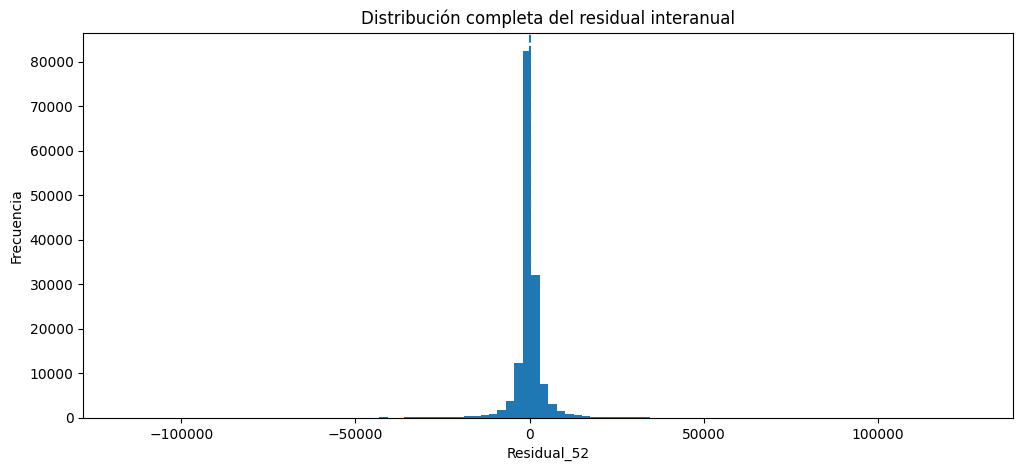

In [41]:
# =============================================================================
# DISTRIBUCIÓN COMPLETA DEL RESIDUAL
# =============================================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    residual_analysis["Residual_52"],
    bins=100
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Residual_52")
plt.ylabel("Frecuencia")
plt.title("Distribución completa del residual interanual")

plt.show()

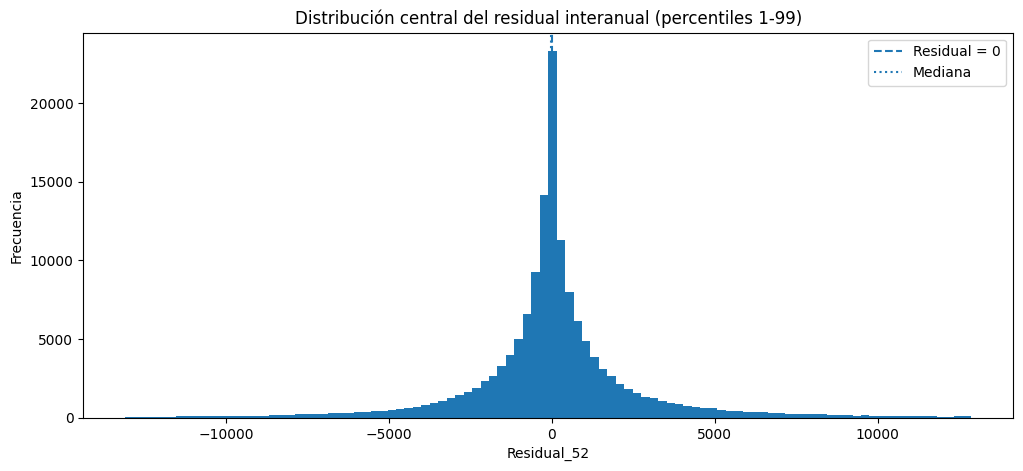

In [42]:
# =============================================================================
# DISTRIBUCIÓN CENTRAL DEL RESIDUAL (P1 - P99)
# =============================================================================

p01 = residual_analysis["Residual_52"].quantile(0.01)
p99 = residual_analysis["Residual_52"].quantile(0.99)

central_residual = residual_analysis[
    residual_analysis["Residual_52"].between(
        p01,
        p99
    )
]


plt.figure(figsize=(12, 5))

plt.hist(
    central_residual["Residual_52"],
    bins=100
)

plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1.5,
    label="Residual = 0"
)

plt.axvline(
    x=residual_analysis["Residual_52"].median(),
    linestyle=":",
    linewidth=1.5,
    label="Mediana"
)

plt.xlabel("Residual_52")
plt.ylabel("Frecuencia")
plt.title(
    "Distribución central del residual interanual "
    "(percentiles 1-99)"
)

plt.legend()
plt.show()

In [43]:
# =============================================================================
# ERROR DEL BASELINE SEGÚN SEMANA FESTIVA
# =============================================================================

holiday_error = (
    residual_analysis
    .groupby("IsHoliday")
    .agg(
        Count=("Residual_52", "size"),

        Mean_Residual=(
            "Residual_52",
            "mean"
        ),

        Median_Residual=(
            "Residual_52",
            "median"
        ),

        MAE=(
            "Abs_Residual_52",
            "mean"
        ),

        RMSE=(
            "Squared_Residual_52",
            lambda x: np.sqrt(x.mean())
        ),

        Std_Residual=(
            "Residual_52",
            "std"
        )
    )
)

display(holiday_error)

,Count,Mean_Residual,Median_Residual,MAE,RMSE,Std_Residual
IsHoliday,,,,,,
False,137576,-51.61,-22.45,"1,977.01","4,279.84","4,279.54"
True,11528,550.03,66.07,"2,255.01","4,610.63","4,577.91"


In [44]:
# =============================================================================
# ERROR DEL BASELINE POR TIENDA
# =============================================================================

residual_by_store = (
    residual_analysis
    .groupby("Store")
    .agg(
        Count=("Residual_52", "size"),

        Mean_Residual=(
            "Residual_52",
            "mean"
        ),

        Median_Residual=(
            "Residual_52",
            "median"
        ),

        MAE=(
            "Abs_Residual_52",
            "mean"
        ),

        RMSE=(
            "Squared_Residual_52",
            lambda x: np.sqrt(x.mean())
        )
    )
    .sort_values(
        "MAE",
        ascending=False
    )
)

display(residual_by_store)

,Count,Mean_Residual,Median_Residual,MAE,RMSE
Store,,,,,
35,3389,"-3,190.11","-1,635.24","3,960.50","6,939.05"
14,3606,"-1,743.61",-732.42,"3,677.18","7,965.67"
4,3689,"2,295.34",790.25,"3,435.75","6,116.57"
23,3563,64.44,-41.87,"3,422.42","6,434.06"
18,3464,"-1,459.61",-620.57,"3,121.76","6,117.26"
20,3650,293.16,38.28,"3,114.37","6,537.21"
27,3672,"-1,183.25",-518.00,"2,967.85","5,682.68"
13,3765,740.14,43.68,"2,880.67","6,367.27"
10,3715,-670.52,-188.49,"2,753.16","6,557.44"


In [45]:
# =============================================================================
# ERROR DEL BASELINE POR DEPARTAMENTO
# =============================================================================

residual_by_dept = (
    residual_analysis
    .groupby("Dept")
    .agg(
        Count=("Residual_52", "size"),

        Mean_Residual=(
            "Residual_52",
            "mean"
        ),

        Median_Residual=(
            "Residual_52",
            "median"
        ),

        MAE=(
            "Abs_Residual_52",
            "mean"
        ),

        RMSE=(
            "Squared_Residual_52",
            lambda x: np.sqrt(x.mean())
        )
    )
    .sort_values(
        "MAE",
        ascending=False
    )
)

display(residual_by_dept)

,Count,Mean_Residual,Median_Residual,MAE,RMSE
Dept,,,,,
65,52,"-8,297.00","-10,578.84","10,615.57","12,138.17"
72,2180,"-1,495.91",-37.19,"8,476.44","13,865.15"
38,2340,"1,337.15","1,764.61","7,366.20","10,015.92"
92,2340,"3,667.74","3,245.69","6,734.90","9,527.72"
95,2340,411.75,"1,103.74","5,538.51","7,940.81"
...,...,...,...,...,...
60,1711,-2.65,7.00,110.47,163.24
77,1,41.94,41.94,41.94,41.94
51,279,-17.27,-16.09,33.33,47.77


In [46]:
# =============================================================================
# MAYORES ERRORES DEL BASELINE ANUAL
# =============================================================================

extreme_residuals = (
    residual_analysis
    .sort_values(
        "Abs_Residual_52",
        ascending=False
    )
)

columns_extremes = [
    "Store",
    "Dept",
    "Date",
    "Weekly_Sales",
    "Lag_52",
    "Residual_52",
    "Abs_Residual_52",
    "IsHoliday",
    "Temperature",
    "Fuel_Price",
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",
    "CPI",
    "Unemployment"
]

display(
    extreme_residuals[
        columns_extremes
    ].head(30)
)

,Store,Dept,Date,Weekly_Sales,Lag_52,Residual_52,Abs_Residual_52,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment
85565,13,1,2011-04-22,"154,137.88","27,434.49","126,703.38","126,703.38",False,47.55,3.65,0.00,0.00,0.00,0.00,0.00,128.96,7.19
136139,20,1,2011-04-22,"143,220.95","26,674.31","116,546.64","116,546.64",False,52.56,3.89,0.00,0.00,0.00,0.00,0.00,208.48,7.29
93192,14,1,2011-04-22,"133,744.52","17,282.65","116,461.87","116,461.87",False,53.04,3.89,0.00,0.00,0.00,0.00,0.00,185.67,8.52
93189,14,1,2011-04-01,"32,014.12","148,029.47","-116,015.35","116,015.35",False,37.27,3.64,0.00,0.00,0.00,0.00,0.00,185.18,8.52
69426,10,72,2011-12-16,"158,010.38","268,789.69","-110,779.31","110,779.31",False,50.53,3.49,"2,200.27",337.44,"1,203.16",158.52,"3,475.95",129.90,7.87
69427,10,72,2011-12-23,"296,628.28","404,245.03","-107,616.75","107,616.75",False,48.36,3.54,300.02,77.73,"2,432.01",108.37,"4,078.21",129.98,7.87
136136,20,1,2011-04-01,"42,700.12","149,743.97","-107,043.84","107,043.84",False,32.43,3.64,0.00,0.00,0.00,0.00,0.00,207.88,7.29
63690,10,1,2011-04-01,"31,697.55","131,853.02","-100,155.47","100,155.47",False,67.64,3.77,0.00,0.00,0.00,0.00,0.00,128.72,8.49
98724,14,72,2011-11-25,"375,948.31","474,330.09","-98,381.78","98,381.78",True,48.71,3.49,286.52,54.00,"89,402.64",13.00,"1,915.80",188.35,8.52
93851,14,7,2011-12-23,"260,735.86","356,867.25","-96,131.39","96,131.39",False,42.27,3.39,924.14,112.73,"2,127.77",80.02,"4,638.81",188.93,8.52


In [47]:
# =============================================================================
# ERROR DEL BASELINE SEGÚN VOLUMEN DE VENTAS
# =============================================================================

residual_analysis["Sales_Volume_Group"] = pd.qcut(
    residual_analysis["Lag_52"],
    q=5,
    duplicates="drop"
)

error_by_volume = (
    residual_analysis
    .groupby(
        "Sales_Volume_Group",
        observed=True
    )
    .agg(
        Count=(
            "Residual_52",
            "size"
        ),

        Mean_Lag52=(
            "Lag_52",
            "mean"
        ),

        MAE=(
            "Abs_Residual_52",
            "mean"
        ),

        RMSE=(
            "Squared_Residual_52",
            lambda x: np.sqrt(x.mean())
        )
    )
)

display(error_by_volume)

,Count,Mean_Lag52,MAE,RMSE
Sales_Volume_Group,,,,
"(-4988.941, 1660.93]",29822,593.29,299.79,943.75
"(1660.93, 5325.392]",29820,"3,367.36",700.96,"1,068.52"
"(5325.392, 11867.536]",29820,"8,293.41","1,341.46","2,145.56"
"(11867.536, 25868.639]",29821,"17,662.88","2,298.98","3,611.04"
"(25868.639, 693099.375]",29821,"52,314.56","5,351.34","8,546.70"


### 7.2. Estructura del error y comparación relativa

Una vez comprobado que `Lag_52` proporciona una referencia competitiva, resulta interesante analizar **cuándo y dónde se equivoca**. El objetivo de este apartado no es todavía mejorar el modelo, sino estudiar si los errores del baseline presentan algún patrón que pueda aprovecharse posteriormente.

En primer lugar, el residuo interanual se concentra alrededor de cero, aunque presenta colas largas. Su media y mediana son próximas a cero, por lo que no parece existir un sesgo global importante que pueda corregirse simplemente sumando o restando una cantidad constante a `Lag_52`. Los errores parecen depender más bien de determinadas observaciones o contextos concretos.

Uno de esos contextos pueden ser las semanas festivas. El MAE pasa aproximadamente de 1.977 en semanas ordinarias a 2.255 en semanas festivas, un incremento cercano al 14 %. Además, el residuo medio es positivo durante estas semanas, lo que indica que, en promedio, `Lag_52` tiende a quedarse por debajo de las ventas observadas. Este resultado debe interpretarse con cautela: retroceder 52 semanas equivale a 364 días y algunas festividades no se celebran exactamente en la misma fecha o semana de un año a otro.

También aparecen diferencias importantes entre tiendas y departamentos. Sin embargo, comparar únicamente su MAE puede resultar engañoso. Una tienda con un volumen de ventas elevado puede presentar errores absolutos mayores simplemente porque trabaja con cantidades mayores, sin que esto implique necesariamente que sus ventas sean menos predecibles.

Esta relación con la escala se observa claramente al agrupar las observaciones según el valor de `Lag_52`: el MAE pasa de aproximadamente 300 en el quintil de menor volumen a más de 5.300 en el quintil superior. Por tanto, parte de las diferencias de error entre grupos puede explicarse simplemente por su distinto nivel de ventas.

Para complementar este análisis incorporamos una medida de error relativo agregado:

$$
RAE_g =
\frac{
\sum_{i\in g}|Y_i-Y_{i-52}|
}{
\sum_{i\in g}|Y_{i-52}|
}
$$

donde $g$ representa una tienda o departamento.

Esta medida compara el error absoluto acumulado de cada grupo con su volumen de ventas de referencia. De esta forma, permite diferenciar entre un grupo que presenta un MAE elevado principalmente porque vende mucho y otro cuyas ventas se alejan considerablemente de las del año anterior también en términos relativos.

El `RAE` se utiliza únicamente como herramienta de diagnóstico y **no sustituye al WMAE como métrica de evaluación de los modelos**. Tampoco corresponde a una media de errores porcentuales individuales, sino a una comparación agregada entre el error absoluto y el volumen de referencia. Para evitar conclusiones basadas en grupos con pocas observaciones, en el análisis por departamentos se consideran únicamente aquellos con al menos 100 registros.

En conjunto, este análisis sugiere que los errores de `Lag_52` no se distribuyen de forma homogénea: dependen del contexto y de la escala de las ventas. Estos patrones servirán para orientar los siguientes experimentos, aunque será necesario comprobar en validación si realmente contienen información útil para mejorar las predicciones.

In [48]:
# =============================================================================
# ERROR RELATIVO AGREGADO POR GRUPO
# =============================================================================

def grouped_residual_metrics(df, group_col):

    result = (
        df
        .groupby(group_col)
        .agg(
            Count=(
                "Residual_52",
                "size"
            ),

            Mean_Lag52=(
                "Lag_52",
                "mean"
            ),

            Mean_Residual=(
                "Residual_52",
                "mean"
            ),

            Median_Residual=(
                "Residual_52",
                "median"
            ),

            MAE=(
                "Abs_Residual_52",
                "mean"
            ),

            RMSE=(
                "Squared_Residual_52",
                lambda x: np.sqrt(x.mean())
            ),

            Total_Abs_Error=(
                "Abs_Residual_52",
                "sum"
            )
        )
    )

    # Denominador agregado:
    # suma del valor absoluto de las ventas de hace 52 semanas
    abs_lag_sum = (
        df
        .assign(Abs_Lag52=df["Lag_52"].abs())
        .groupby(group_col)["Abs_Lag52"]
        .sum()
    )

    result["Relative_Absolute_Error"] = (
        result["Total_Abs_Error"]
        / abs_lag_sum.replace(0, np.nan)
    )

    return result

In [49]:
# =============================================================================
# ERROR AJUSTADO POR ESCALA - TIENDA
# =============================================================================

store_error_analysis = grouped_residual_metrics(
    residual_analysis,
    "Store"
)

print("Tiendas con mayor MAE absoluto:")
display(
    store_error_analysis
    .sort_values("MAE", ascending=False)
    .head(15)
)

print("\nTiendas con mayor error relativo:")
display(
    store_error_analysis
    .sort_values(
        "Relative_Absolute_Error",
        ascending=False
    )
    .head(15)
)

Tiendas con mayor MAE absoluto:


,Count,Mean_Lag52,Mean_Residual,Median_Residual,MAE,RMSE,Total_Abs_Error,Relative_Absolute_Error
Store,,,,,,,,
35,3389,"16,175.32","-3,190.11","-1,635.24","3,960.50","6,939.05","13,422,150.00",0.24
14,3606,"31,165.34","-1,743.61",-732.42,"3,677.18","7,965.67","13,259,919.00",0.12
4,3689,"27,949.42","2,295.34",790.25,"3,435.75","6,116.57","12,674,477.00",0.12
23,3563,"20,218.30",64.44,-41.87,"3,422.42","6,434.06","12,194,094.00",0.17
18,3464,"17,146.29","-1,459.61",-620.57,"3,121.76","6,117.26","10,813,764.00",0.18
20,3650,"29,860.11",293.16,38.28,"3,114.37","6,537.21","11,367,448.00",0.10
27,3672,"26,155.91","-1,183.25",-518.00,"2,967.85","5,682.68","10,897,932.00",0.11
13,3765,"27,118.57",740.14,43.68,"2,880.67","6,367.27","10,845,737.00",0.11
10,3715,"27,264.91",-670.52,-188.49,"2,753.16","6,557.44","10,228,007.00",0.10



Tiendas con mayor error relativo:


,Count,Mean_Lag52,Mean_Residual,Median_Residual,MAE,RMSE,Total_Abs_Error,Relative_Absolute_Error
Store,,,,,,,,
35,3389,"16,175.32","-3,190.11","-1,635.24","3,960.50","6,939.05","13,422,150.00",0.24
36,2116,"10,735.57","-1,914.66",-203.29,"2,226.46","4,702.21","4,711,185.50",0.21
3,3214,"6,290.05",187.58,165.00,"1,202.24","3,263.26","3,863,991.00",0.19
7,3415,"8,136.12",881.46,305.77,"1,497.96","2,840.04","5,115,543.00",0.18
18,3464,"17,146.29","-1,459.61",-620.57,"3,121.76","6,117.26","10,813,764.00",0.18
33,2177,"6,313.21",-342.49,7.28,"1,071.23","2,646.07","2,332,060.25",0.17
23,3563,"20,218.30",64.44,-41.87,"3,422.42","6,434.06","12,194,094.00",0.17
9,3096,"8,716.98",564.80,209.92,"1,262.87","2,349.86","3,909,853.00",0.14
5,3187,"4,997.76",189.53,44.00,716.60,"1,559.03","2,283,813.75",0.14


In [50]:
# =============================================================================
# ERROR AJUSTADO POR ESCALA - DEPARTAMENTO
# =============================================================================

dept_error_analysis = grouped_residual_metrics(
    residual_analysis,
    "Dept"
)

print("Departamentos con mayor MAE absoluto:")
display(
    dept_error_analysis
    .sort_values("MAE", ascending=False)
    .head(20)
)

print("\nDepartamentos con mayor error relativo:")
display(
    dept_error_analysis[
        dept_error_analysis["Count"] >= 100
    ]
    .sort_values(
        "Relative_Absolute_Error",
        ascending=False
    )
    .head(20)
)

Departamentos con mayor MAE absoluto:


,Count,Mean_Lag52,Mean_Residual,Median_Residual,MAE,RMSE,Total_Abs_Error,Relative_Absolute_Error
Dept,,,,,,,,
65,52,"48,842.87","-8,297.00","-10,578.84","10,615.57","12,138.17","552,009.44",0.22
72,2180,"54,062.50","-1,495.91",-37.19,"8,476.44","13,865.15","18,478,648.00",0.16
38,2340,"60,014.95","1,337.15","1,764.61","7,366.20","10,015.92","17,236,916.00",0.12
92,2340,"72,279.31","3,667.74","3,245.69","6,734.90","9,527.72","15,759,665.00",0.09
95,2340,"68,842.63",411.75,"1,103.74","5,538.51","7,940.81","12,960,112.00",0.08
5,2262,"24,273.18","-2,133.09",-336.07,"4,956.71","9,164.42","11,212,084.00",0.20
90,2340,"43,340.18","3,078.88","2,346.61","4,472.10","6,342.56","10,464,720.00",0.10
1,2340,"19,323.11",131.49,43.59,"4,412.97","11,210.66","10,326,342.00",0.23
7,2340,"25,870.13",-592.77,-111.44,"4,357.82","8,421.82","10,197,305.00",0.17



Departamentos con mayor error relativo:


,Count,Mean_Lag52,Mean_Residual,Median_Residual,MAE,RMSE,Total_Abs_Error,Relative_Absolute_Error
Dept,,,,,,,,
51,279,32.59,-17.27,-16.09,33.33,47.77,"9,299.45",1.01
45,446,26.90,-3.45,0.50,22.50,37.23,"10,033.39",0.80
54,1699,204.90,-143.57,-95.16,157.51,234.68,"267,617.84",0.76
48,465,"1,261.67",170.18,74.00,770.61,"1,088.45","358,334.75",0.61
59,2236,"1,179.28",-619.17,-253.66,633.53,"1,882.57","1,416,572.50",0.54
58,1501,"4,219.56",-812.00,-658.00,"1,992.86","2,910.09","2,991,279.75",0.47
41,1914,"1,959.29",206.13,119.50,870.64,"1,731.07","1,666,397.00",0.44
36,1924,"1,975.14",109.18,51.50,749.39,"1,158.65","1,441,835.75",0.38
19,1344,"1,909.31",-217.28,-87.69,612.69,"1,073.50","823,451.31",0.32


In [51]:
# =============================================================================
# CONTRIBUCIÓN DE CADA NIVEL DE VENTAS AL ERROR ABSOLUTO TOTAL
# =============================================================================

error_by_volume["Total_Absolute_Error"] = (
    error_by_volume["Count"]
    * error_by_volume["MAE"]
)

error_by_volume["Error_Contribution_pct"] = (
    100
    * error_by_volume["Total_Absolute_Error"]
    / error_by_volume["Total_Absolute_Error"].sum()
)

display(error_by_volume)

,Count,Mean_Lag52,MAE,RMSE,Total_Absolute_Error,Error_Contribution_pct
Sales_Volume_Group,,,,,,
"(-4988.941, 1660.93]",29822,593.29,299.79,943.75,"8,940,344.01",3.00
"(1660.93, 5325.392]",29820,"3,367.36",700.96,"1,068.52","20,902,580.53",7.01
"(5325.392, 11867.536]",29820,"8,293.41","1,341.46","2,145.56","40,002,241.39",13.42
"(11867.536, 25868.639]",29821,"17,662.88","2,298.98","3,611.04","68,557,772.79",23.01
"(25868.639, 693099.375]",29821,"52,314.56","5,351.34","8,546.70","159,582,349.16",53.55


### 7.3. Correspondencia de las semanas festivas

Comprobamos si `IsHoliday` coincide entre la fecha actual y la situada 52 semanas antes en las observaciones del entrenamiento interno utilizadas para el análisis. Esta comprobación se refiere al indicador binario de festivo, no a la identidad de cada campaña.

In [52]:
# =============================================================================
# FESTIVIDAD ACTUAL VS FESTIVIDAD 52 SEMANAS ANTES
# =============================================================================

holiday_lookup = (
    train_model[
        [
            "Store",
            "Dept",
            "Date",
            "IsHoliday"
        ]
    ]
    .rename(
        columns={
            "Date": "Lag_52_Date",
            "IsHoliday": "Lag_52_IsHoliday"
        }
    )
)

residual_context = residual_analysis.merge(
    holiday_lookup,
    on=[
        "Store",
        "Dept",
        "Lag_52_Date"
    ],
    how="left",
    validate="many_to_one"
)


residual_context["Holiday_Mismatch"] = (
    residual_context["IsHoliday"]
    != residual_context["Lag_52_IsHoliday"]
)

In [53]:
# =============================================================================
# ERROR SEGÚN COINCIDENCIA DEL FESTIVO
# =============================================================================

holiday_alignment = (
    residual_context
    .groupby(
        [
            "IsHoliday",
            "Lag_52_IsHoliday"
        ],
        observed=True
    )
    .agg(
        Count=(
            "Residual_52",
            "size"
        ),

        Mean_Residual=(
            "Residual_52",
            "mean"
        ),

        Median_Residual=(
            "Residual_52",
            "median"
        ),

        MAE=(
            "Abs_Residual_52",
            "mean"
        ),

        RMSE=(
            "Squared_Residual_52",
            lambda x: np.sqrt(x.mean())
        )
    )
)

display(holiday_alignment)


print(
    "\nPorcentaje de observaciones con cambio "
    "en la condición de festivo:"
)

print(
    f"{100 * residual_context['Holiday_Mismatch'].mean():.2f}%"
)

,,Count,Mean_Residual,Median_Residual,MAE,RMSE
IsHoliday,Lag_52_IsHoliday,,,,,
False,False,137576,-51.61,-22.45,"1,977.01","4,279.84"
True,True,11528,550.03,66.07,"2,255.01","4,610.63"



Porcentaje de observaciones con cambio en la condición de festivo:
0.00%


### 7.4. Síntesis del análisis del residuo

La comparación en validación muestra que las ventas registradas 52 semanas antes son una referencia competitiva frente a las regresiones probadas. En el análisis descriptivo del entrenamiento interno, el residuo interanual,

$$
\Delta Y_t = Y_t-Y_{t-52},
$$

se encuentra fuertemente concentrado alrededor de cero, por lo que no se observa una corrección global evidente que permita mejorar el baseline mediante un simple desplazamiento de nivel.

Sin embargo, el error no presenta un comportamiento homogéneo. Se observan diferencias relevantes entre tiendas y una fuerte dependencia de la magnitud del error absoluto respecto al volumen de ventas. En particular, el quintil de observaciones con mayor volumen concentra aproximadamente el 53,6 % del error absoluto total, mientras que los dos quintiles superiores acumulan aproximadamente el 76,6 %.

Estas diferencias motivan intentar predecir el residuo, aunque todavía no demuestran que las variables disponibles permitan mejorarlo fuera del entrenamiento. En esta misma muestra no aparecen cambios en la condición de festivo entre la fecha actual y su retardo: el porcentaje de discrepancias es del 0 %.

En consecuencia, el análisis exploratorio del residual se considera suficiente para orientar el modelado posterior. A partir de este punto, el objetivo deja de ser caracterizar adicionalmente el error y pasa a ser determinar si las diferencias observadas en las condiciones respecto al ejercicio anterior permiten predecir:

$$
\Delta Y_t.
$$

Para ello se generarán características interanuales de la forma:

$$
\Delta X_t = X_t-X_{t-52},
$$

cuando dicha operación tenga interpretación y la información necesaria se encuentre disponible en el momento de efectuar la predicción.

## 8. Construcción de cambios interanuales

Una vez reformulado el problema para predecir el residuo respecto a `Lag_52`, resulta natural replantearse también el papel de las variables explicativas. Si el objetivo es explicar por qué las ventas difieren de las del año anterior, es posible que las variaciones experimentadas por algunas variables entre ambos años sean más informativas que sus valores absolutos.

Con esta idea se construyen `Delta_Temperature` y `Delta_Fuel_Price`, calculadas como la diferencia entre el valor actual y el registrado 52 semanas antes:

$$
\Delta X_t = X_t - X_{t-52}.
$$

El objetivo no es asumir que estas variables mejorarán el modelo, sino comprobar si los cambios interanuales en las condiciones ambientales y económicas ayudan a explicar el residuo. Este análisis servirá también para decidir posteriormente si estas variables aportan suficiente información como para mantenerse en el conjunto final de características.

Estas variables están definidas por tienda y fecha, por lo que el histórico de consulta elimina las repeticiones debidas a los departamentos. Después se recupera exactamente la misma partición temporal y se calcula `Residual_52`.

Se utilizan las condiciones actuales proporcionadas por el conjunto de datos; en este trabajo no se construyen modelos para pronosticar la temperatura o el precio del combustible. En una aplicación real, sería necesario garantizar la disponibilidad de estas variables en el momento de realizar la predicción.

In [54]:
# =============================================================================
# CREACIÓN DE VARIABLES INTERANUALES
# =============================================================================

def add_interannual_features(df, historical_data):
    """
    Añade variables que representan el cambio respecto a exactamente
    52 semanas antes para la misma tienda.

    Variables creadas:
        - Delta_Temperature
        - Delta_Fuel_Price
    """

    df = df.copy()

    # -------------------------------------------------------------------------
    # Fecha de referencia interanual
    # -------------------------------------------------------------------------

    if "Lag_52_Date" not in df.columns:
        df["Lag_52_Date"] = (
            df["Date"] - pd.Timedelta(weeks=52)
        )


    # -------------------------------------------------------------------------
    # Tabla histórica Store-Date
    # -------------------------------------------------------------------------
    # Temperature y Fuel_Price son características de tienda/fecha,
    # por lo que eliminamos las repeticiones introducidas por Dept.
    # -------------------------------------------------------------------------

    historical_lookup = (
        historical_data[
            [
                "Store",
                "Date",
                "Temperature",
                "Fuel_Price"
            ]
        ]
        .drop_duplicates(
            subset=["Store", "Date"]
        )
        .rename(
            columns={
                "Date": "Lag_52_Date",
                "Temperature": "Temperature_Lag_52",
                "Fuel_Price": "Fuel_Price_Lag_52"
            }
        )
    )


    # -------------------------------------------------------------------------
    # Incorporación de los valores del año anterior
    # -------------------------------------------------------------------------

    df = df.merge(
        historical_lookup,
        on=[
            "Store",
            "Lag_52_Date"
        ],
        how="left",
        validate="many_to_one"
    )


    # -------------------------------------------------------------------------
    # Cambios interanuales
    # -------------------------------------------------------------------------

    df["Delta_Temperature"] = (
        df["Temperature"]
        - df["Temperature_Lag_52"]
    ).astype(np.float32)

    df["Delta_Fuel_Price"] = (
        df["Fuel_Price"]
        - df["Fuel_Price_Lag_52"]
    ).astype(np.float32)


    return df

In [55]:
# =============================================================================
# APLICACIÓN DE VARIABLES INTERANUALES
# =============================================================================

train_features = add_interannual_features(
    train_lagged,
    historical_data=train_model
)

test_features = add_interannual_features(
    test_lagged,
    historical_data=train_model
)

In [56]:
# =============================================================================
# COMPROBACIÓN DE VARIABLES INTERANUALES
# =============================================================================

delta_features = [
    "Delta_Temperature",
    "Delta_Fuel_Price"
]


def check_delta_features(df, name):

    print(name)
    print("=" * len(name))

    for col in delta_features:

        available = df[col].notna().sum()
        missing = df[col].isna().sum()

        print(
            f"{col}: "
            f"{available:,} disponibles "
            f"({available / len(df) * 100:.2f}%) | "
            f"{missing:,} ausentes "
            f"({missing / len(df) * 100:.2f}%)"
        )

    print()


check_delta_features(
    train_features,
    "TRAIN COMPLETO"
)

check_delta_features(
    test_features,
    "TEST"
)

TRAIN COMPLETO
Delta_Temperature: 269,196 disponibles (63.86%) | 152,374 ausentes (36.14%)
Delta_Fuel_Price: 269,196 disponibles (63.86%) | 152,374 ausentes (36.14%)

TEST
====
Delta_Temperature: 115,064 disponibles (100.00%) | 0 ausentes (0.00%)
Delta_Fuel_Price: 115,064 disponibles (100.00%) | 0 ausentes (0.00%)



In [57]:
# =============================================================================
# RECONSTRUCCIÓN DEL SPLIT TEMPORAL
# =============================================================================

train_internal_features = (
    train_features[
        train_features["Date"] < validation_start_date
    ]
    .copy()
)

validation_features = (
    train_features[
        train_features["Date"] >= validation_start_date
    ]
    .copy()
)


train_internal_features = (
    train_internal_features
    .sort_values(
        ["Store", "Dept", "Date"]
    )
    .reset_index(drop=True)
)

validation_features = (
    validation_features
    .sort_values(
        ["Store", "Dept", "Date"]
    )
    .reset_index(drop=True)
)

test_features = (
    test_features
    .sort_values(
        ["Store", "Dept", "Date"]
    )
    .reset_index(drop=True)
)

In [58]:
# =============================================================================
# CREACIÓN DE LA VARIABLE OBJETIVO RESIDUAL
# =============================================================================

for df in [
    train_internal_features,
    validation_features
]:

    df["Residual_52"] = (
        df["Weekly_Sales"]
        - df["Lag_52"]
    ).astype(np.float32)

### 8.1. Muestras disponibles para el modelo residual

La reformulación del problema implica una consecuencia inmediata: para calcular el residuo es imprescindible disponer de `Lag_52`. Si no existe una venta correspondiente a la misma semana del año anterior, tampoco puede definirse la variable objetivo que el modelo debe aprender.

Por este motivo, a partir de este apartado el desarrollo se realiza únicamente sobre las observaciones con `Lag_52` disponible. Esto da lugar a **149.104 observaciones de entrenamiento interno** y **112.437 observaciones de validación**.

A diferencia de la referencia estacional inicial, aquí no se sustituyen los retardos ausentes mediante la mediana. Hacerlo permitiría mantener todas las filas, pero introduciría residuos artificiales que no representarían la diferencia real respecto al año anterior y podrían perjudicar el aprendizaje del modelo. Por ello, estas observaciones se excluyen del entrenamiento y de la evaluación.

Es importante señalar que esta limitación afecta únicamente al inicio del histórico. Las primeras 52 semanas no disponen de una referencia anual porque simplemente no existe un año previo con el que compararlas. Sin embargo, una vez superado ese periodo inicial, todas las observaciones posteriores cuentan con `Lag_52`.

Por este motivo, esta pérdida de observaciones solo afecta al entrenamiento del modelo. En el conjunto de test, `Lag_52` puede calcularse utilizando el histórico formado por los conjuntos de entrenamiento y validación, por lo que todas las observaciones dispondrán de una referencia anual y podrán ser predichas por el modelo final.

In [59]:
# =============================================================================
# MUESTRAS VÁLIDAS PARA EL MODELADO RESIDUAL
# =============================================================================

train_residual = (
    train_internal_features[
        train_internal_features["Residual_52"].notna()
    ]
    .copy()
)

validation_residual = (
    validation_features[
        validation_features["Residual_52"].notna()
    ]
    .copy()
)


print("TRAIN RESIDUAL")
print(
    f"Observaciones: "
    f"{len(train_residual):,} / "
    f"{len(train_internal_features):,}"
)

print(
    f"Porcentaje utilizado: "
    f"{100 * len(train_residual) / len(train_internal_features):.2f}%"
)


print("\nVALIDACIÓN RESIDUAL")
print(
    f"Observaciones: "
    f"{len(validation_residual):,} / "
    f"{len(validation_features):,}"
)

print(
    f"Porcentaje utilizado: "
    f"{100 * len(validation_residual) / len(validation_features):.2f}%"
)

TRAIN RESIDUAL
Observaciones: 149,104 / 305,982
Porcentaje utilizado: 48.73%

VALIDACIÓN RESIDUAL
Observaciones: 112,437 / 115,588
Porcentaje utilizado: 97.27%


In [60]:
# =============================================================================
# DISPONIBILIDAD EN EL DATASET RESIDUAL
# =============================================================================

print("TRAIN RESIDUAL")

display(
    train_residual[
        [
            "Delta_Temperature",
            "Delta_Fuel_Price"
        ]
    ]
    .isna()
    .sum()
    .to_frame("NaN")
)


print("\nVALIDACIÓN RESIDUAL")

display(
    validation_residual[
        [
            "Delta_Temperature",
            "Delta_Fuel_Price"
        ]
    ]
    .isna()
    .sum()
    .to_frame("NaN")
)

TRAIN RESIDUAL


,NaN
Delta_Temperature,0
Delta_Fuel_Price,0



VALIDACIÓN RESIDUAL


,NaN
Delta_Temperature,0
Delta_Fuel_Price,0


## 9. Regresión lineal del residuo

El modelo utiliza 23 variables de entrada. Respecto a la regresión inicial, se incorporan los cambios interanuales de temperatura y combustible (`Delta_Temperature` y `Delta_Fuel_Price`), mientras que `CPI` y `Unemployment` quedan excluidas de esta configuración. Como ya se comentó en el primer notebook, estas variables presentan problemas de disponibilidad en el conjunto de test, aunque en este apartado no se pretende evaluar de forma aislada el impacto de su eliminación.

Dado que el modelo residual trabaja únicamente con observaciones que disponen de `Lag_52`, el indicador `Lag_52_isna` deja de aportar información y se elimina del conjunto de variables. En cambio, se mantienen los indicadores de ausencia asociados a los `MarkDown`, ya que continúan diferenciando observaciones con y sin información de promociones.

Se aplica el mismo procedimiento de preprocesamiento, ajustado ahora sobre la muestra residual. La regresión se entrena sin ponderación por festivos. Finalmente, el residuo predicho se suma a `Lag_52` para reconstruir la predicción de ventas y comparar su rendimiento con la referencia estacional sobre las mismas observaciones.

In [61]:
# =============================================================================
# VARIABLES DEL MODELO RESIDUAL
# =============================================================================

RESIDUAL_TARGET = "Residual_52"


# -------------------------------------------------------------------------
# Variables categóricas
# -------------------------------------------------------------------------

categorical_features_residual = [
    "Store",
    "Dept",
    "Type"
]


# -------------------------------------------------------------------------
# Variables numéricas
# -------------------------------------------------------------------------

numeric_features_residual = [
    # Nivel de referencia anual
    "Lag_52",

    # Condiciones actuales
    "Temperature",
    "Fuel_Price",

    # Cambios respecto al año anterior
    "Delta_Temperature",
    "Delta_Fuel_Price",

    # Promociones actuales
    "MarkDown1",
    "MarkDown2",
    "MarkDown3",
    "MarkDown4",
    "MarkDown5",

    # Características estructurales
    "Size",

    # Temporalidad
    "TimeIndex",
    "WeekSin",
    "WeekCos"
]


# -------------------------------------------------------------------------
# Variables binarias
# -------------------------------------------------------------------------

binary_features_residual = [
    "IsHoliday",

    "MarkDown1_isna",
    "MarkDown2_isna",
    "MarkDown3_isna",
    "MarkDown4_isna",
    "MarkDown5_isna"
]


residual_features = (
    categorical_features_residual
    + numeric_features_residual
    + binary_features_residual
)


print(
    "Número de variables originales:",
    len(residual_features)
)

print("\nVariables utilizadas:")
for col in residual_features:
    print(" -", col)

Número de variables originales: 23

Variables utilizadas:
 - Store
 - Dept
 - Type
 - Lag_52
 - Temperature
 - Fuel_Price
 - Delta_Temperature
 - Delta_Fuel_Price
 - MarkDown1
 - MarkDown2
 - MarkDown3
 - MarkDown4
 - MarkDown5
 - Size
 - TimeIndex
 - WeekSin
 - WeekCos
 - IsHoliday
 - MarkDown1_isna
 - MarkDown2_isna
 - MarkDown3_isna
 - MarkDown4_isna
 - MarkDown5_isna


In [62]:
# =============================================================================
# CREACIÓN DE X E y PARA EL MODELO RESIDUAL
# =============================================================================

X_train_residual = train_residual[
    residual_features
].copy()

y_train_residual = train_residual[
    RESIDUAL_TARGET
].copy()


X_val_residual = validation_residual[
    residual_features
].copy()

y_val_residual = validation_residual[
    RESIDUAL_TARGET
].copy()


print("TRAIN RESIDUAL")
print("X:", X_train_residual.shape)
print("y:", y_train_residual.shape)

print("\nVALIDACIÓN RESIDUAL")
print("X:", X_val_residual.shape)
print("y:", y_val_residual.shape)

TRAIN RESIDUAL
X: (149104, 23)
y: (149104,)

VALIDACIÓN RESIDUAL
X: (112437, 23)
y: (112437,)


In [63]:
# =============================================================================
# COMPROBACIÓN DE VALORES AUSENTES
# =============================================================================

print("NaN en TRAIN:")
display(
    X_train_residual
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("NaN")
)

print("\nNaN en VALIDACIÓN:")
display(
    X_val_residual
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .to_frame("NaN")
)

NaN en TRAIN:


,NaN



NaN en VALIDACIÓN:


,NaN


In [64]:
# =============================================================================
# PREPROCESAMIENTO DEL MODELO RESIDUAL
# =============================================================================

numeric_transformer_residual = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_transformer_residual = Pipeline(
    steps=[
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)


preprocessor_residual = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer_residual,
            numeric_features_residual
        ),
        (
            "categorical",
            categorical_transformer_residual,
            categorical_features_residual
        ),
        (
            "binary",
            "passthrough",
            binary_features_residual
        )
    ],
    remainder="drop"
)

In [65]:
# =============================================================================
# MODELO LINEAL RESIDUAL
# =============================================================================

linear_residual_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_residual
        ),
        (
            "regressor",
            LinearRegression()
        )
    ]
)


linear_residual_model = obtener_modelo_lineal(
    nombre='regresion_residual',
    modelo_nuevo=linear_residual_model,
    X=X_train_residual,
    y=y_train_residual,
    config={'algoritmo': 'LinearRegression',
            'preprocesamiento': 'median-standardscale-onehot',
            'features': residual_features,
            'target': 'Residual_52', 'version': 1}
)


↻ regresion_residual: entrenando (TRAIN=True).
✓ regresion_residual: modelo y firma guardados (sobrescribiendo si existían).


In [66]:
# =============================================================================
# PREDICCIÓN DEL RESIDUAL
# =============================================================================

y_pred_residual = linear_residual_model.predict(
    X_val_residual
)


print(
    "Residual predicho medio:",
    f"{y_pred_residual.mean():,.2f}"
)

print(
    "Residual predicho mínimo:",
    f"{y_pred_residual.min():,.2f}"
)

print(
    "Residual predicho máximo:",
    f"{y_pred_residual.max():,.2f}"
)

Residual predicho medio: 768.99
Residual predicho mínimo: -11,749.35
Residual predicho máximo: 12,162.61


### 9.1. Reconstrucción de las ventas y evaluación

La salida de la regresión es una corrección, no una venta completa. Recuperamos la predicción mediante:

$$
\hat y_t=Lag_{52}(t)+\hat r_t.
$$

Si la corrección fuera siempre cero, obtendríamos exactamente la referencia estacional. Las métricas siguientes permiten comprobar si la corrección aprendida mejora ese punto de partida.

In [67]:
# =============================================================================
# RECONSTRUCCIÓN DE WEEKLY_SALES
# =============================================================================

lag52_validation = (
    validation_residual["Lag_52"]
    .to_numpy()
)

y_val_sales = (
    validation_residual["Weekly_Sales"]
    .to_numpy()
)


y_pred_sales_residual = (
    lag52_validation
    + y_pred_residual
)

In [68]:
# =============================================================================
# EVALUACIÓN DEL MODELO RESIDUAL
# =============================================================================

holiday_weights_residual = np.where(
    validation_residual["IsHoliday"].to_numpy(),
    5,
    1
)


def calculate_metrics(
    y_true,
    y_pred,
    weights
):

    mae_ = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse_ = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    wmae_ = np.average(
        np.abs(
            np.asarray(y_true)
            - np.asarray(y_pred)
        ),
        weights=weights
    )

    r2_ = r2_score(
        y_true,
        y_pred
    )

    return {
        "MAE": mae_,
        "RMSE": rmse_,
        "WMAE": wmae_,
        "R2": r2_
    }

In [69]:
# Baseline
metrics_baseline_residual = calculate_metrics(
    y_val_sales,
    lag52_validation,
    holiday_weights_residual
)


# Regresión residual
metrics_linear_residual = calculate_metrics(
    y_val_sales,
    y_pred_sales_residual,
    holiday_weights_residual
)

In [70]:
# =============================================================================
# COMPARACIÓN BASELINE VS REGRESIÓN RESIDUAL
# =============================================================================

comparison_residual = pd.DataFrame([
    {
        "Modelo": "Baseline Lag_52",
        **metrics_baseline_residual
    },
    {
        "Modelo": "Regresión residual",
        **metrics_linear_residual
    }
])


display(comparison_residual)

,Modelo,MAE,RMSE,WMAE,R2
0,Baseline Lag_52,"1,839.24","3,903.93","1,841.52",0.97
1,Regresión residual,"2,221.27","3,942.16","2,236.99",0.97


## 10. Balance de los primeros modelos

En las 112.437 observaciones de validación con retardo disponible, la regresión residual obtuvo un MAE de 2.221,27, un RMSE de 3.942,16 y un WMAE de 2.236,99. La referencia estacional obtuvo, sobre esas mismas observaciones, 1.839,24, 3.903,93 y 1.841,52, respectivamente.

Por tanto, **la corrección lineal del residuo no mejora la referencia estacional en esta prueba**. Se conserva el experimento porque muestra que detectar diferencias entre grupos no basta para conseguir una mejora predictiva con esta configuración.

El notebook deja definidos la partición temporal, las variables iniciales, las métricas y la referencia que deberá superar cualquier modelo posterior. Las comparaciones realizadas hasta aquí tienen dos alcances distintos:

| Comparación | Muestra de validación | Tratamiento de `Lag_52` |
| --- | ---: | --- |
| Regresión inicial frente a referencia estacional | 115.588 observaciones | Mediana del entrenamiento interno cuando falta el retardo |
| Regresión solo con retardo frente a referencia | 112.437 observaciones | Solo retardos observados |
| Regresión residual frente a referencia | 112.437 observaciones | Solo retardos observados |

Estos resultados orientan la continuación del trabajo, pero no constituyen una evaluación independiente sobre test. La discusión global y las conclusiones del TFM se reservan para el último notebook.

## 11. Exportación y continuación del trabajo

La siguiente etapa de modelización se desarrolla en un notebook independiente. Dejamos preparada su entrada sin modificar aquí los modelos neuronales.

Se exportan las **tablas completas**, no las muestras filtradas utilizadas en la regresión residual:

| Archivo | Observaciones | Contenido |
| --- | ---: | --- |
| `train_internal_nn.parquet` | 305.982 | Entrenamiento interno, variables construidas y residuo cuando puede calcularse |
| `validation_nn.parquet` | 115.588 | Validación, variables construidas y residuo cuando puede calcularse |
| `test_nn.parquet` | 115.064 | Variables construidas, sin ventas observadas ni objetivo residual |

Los retardos ausentes y sus indicadores se conservan. El siguiente notebook deberá indicar qué muestra utiliza antes de comparar sus métricas con las de este. Se mantienen los nombres de archivo y la ruta original para conservar la continuidad entre notebooks.

In [71]:
# =============================================================================
# EXPORTACIÓN CON CONTROL DE CAMBIOS PARA REDES NEURONALES
# =============================================================================
OUTPUT_DIR = Path('/content/drive/MyDrive/TFM/data/neural_networks')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATASETS_NN = {
    'train_internal_nn.parquet': train_internal_features,
    'validation_nn.parquet': validation_features,
    'test_nn.parquet': test_features,
}
RUTA_FIRMA_NN = OUTPUT_DIR / 'export_signature.json'

# Firma de los datos derivados: incluye todas las columnas y observaciones,
# para que los cambios hechos en EDA (y en las transformaciones actuales)
# provoquen la actualización de las exportaciones correspondientes.
digest = hashlib.sha256(b'exportacion-neuronal-v1')
for nombre, frame in DATASETS_NN.items():
    digest.update(nombre.encode())
    digest.update(str(frame.shape).encode())
    digest.update('|'.join(map(str, frame.columns)).encode())
    digest.update('|'.join(map(str, frame.dtypes)).encode())
    digest.update(pd.util.hash_pandas_object(frame, index=False).to_numpy().tobytes())
firma_exportacion = digest.hexdigest()

archivos = [OUTPUT_DIR / nombre for nombre in DATASETS_NN]
faltan_archivos = any(not p.exists() for p in archivos)
firma_anterior = None
if RUTA_FIRMA_NN.exists():
    try:
        firma_anterior = json.loads(
            RUTA_FIRMA_NN.read_text(encoding='utf-8')
        ).get('signature')
    except (OSError, ValueError):
        pass

if TRAIN or faltan_archivos or firma_anterior != firma_exportacion:
    razon = ('TRAIN=True' if TRAIN else
             'faltan datasets exportados' if faltan_archivos else
             'cambiaron los datos derivados o no hay firma previa')
    print(f'↻ Actualizando datasets neuronales: {razon}.')
    for nombre, frame in DATASETS_NN.items():
        frame.to_parquet(OUTPUT_DIR / nombre, index=False)
    RUTA_FIRMA_NN.write_text(
        json.dumps({'signature': firma_exportacion}, indent=2),
        encoding='utf-8'
    )
else:
    print('✓ Datasets neuronales ya guardados y compatibles: sin sobrescritura.')

for ruta in archivos:
    print(' -', ruta)


↻ Actualizando datasets neuronales: TRAIN=True.
 - /content/drive/MyDrive/TFM/data/neural_networks/train_internal_nn.parquet
 - /content/drive/MyDrive/TFM/data/neural_networks/validation_nn.parquet
 - /content/drive/MyDrive/TFM/data/neural_networks/test_nn.parquet


## Nota para la discusión final: interpretación empresarial y límites

Esta reflexión se conserva como parte del razonamiento original. Su desarrollo encaja mejor en el cuarto notebook, dedicado a la discusión y las conclusiones; por ahora queda aquí como nota de trabajo, sin trasladarla ni eliminarla. Las cuestiones comerciales que plantea no son experimentos realizados en este notebook.

El rendimiento de la referencia estacional en la validación utilizada muestra una regularidad interanual que resulta útil para predecir:

$$
Y_t \approx Y_{t-52}
$$

Desde un punto de vista empresarial, este resultado permite plantear distintas preguntas que deben diferenciarse según su naturaleza metodológica.

### Predicción bajo condiciones similares

La primera cuestión consiste en determinar si, manteniendo unas condiciones similares a las del ejercicio anterior —promociones, calendario, características de la tienda y situación económica—, pueden esperarse ventas igualmente similares.

Este problema pertenece al ámbito predictivo. El modelo busca estimar la venta esperada condicionada a la información disponible:

$$
E[Y_t\mid Y_{t-52},X_t]
$$

Los resultados obtenidos muestran que la venta correspondiente al año anterior constituye por sí sola una referencia especialmente potente. No obstante, esta relación debe interpretarse como una regularidad predictiva y no necesariamente como una relación causal. Que unas determinadas promociones aparezcan asociadas a unas determinadas ventas no implica que dichas promociones sean la causa exclusiva de ese nivel de ventas.

### Optimización de las decisiones comerciales

Una segunda cuestión empresarial consiste en determinar si sería posible reducir el esfuerzo promocional o los costes manteniendo un nivel similar de ventas.

Este problema puede expresarse conceptualmente como:

$$
\min_{a} C(a)
$$

sujeto a:

$$
E[Y(a)]\geq Y_{\mathrm{objetivo}}
$$

donde $a$ representa una determinada acción comercial y $C(a)$ su coste.

A diferencia de la predicción, esta pregunta requiere estimar qué habría ocurrido bajo decisiones comerciales alternativas, es decir, resultados contrafactuales. El conjunto de datos disponible es observacional y las promociones históricas no fueron asignadas aleatoriamente. Además, las variables `MarkDown` no proporcionan directamente información suficiente sobre el coste de las acciones, el margen comercial o el beneficio obtenido.

En consecuencia, el modelo predictivo desarrollado en este trabajo no permite establecer de forma causal cuál sería el efecto de reducir o modificar una promoción. Este tipo de análisis requeriría un planteamiento específico de inferencia causal, experimentación o, bajo determinados supuestos, métodos de aprendizaje de políticas.

### Robustez ante cambios estructurales

La elevada persistencia interanual observada depende igualmente de que las condiciones futuras mantengan una relación razonablemente similar a la registrada en el histórico.

Un modelo de aprendizaje automático se entrena a partir de una distribución histórica:

$$
P_{\mathrm{train}}(X,Y)
$$

pero acontecimientos económicos o sociales relevantes pueden provocar que la distribución futura sea diferente:

$$
P_{\mathrm{future}}(X,Y)
\neq
P_{\mathrm{train}}(X,Y)
$$

Este fenómeno se conoce de forma general como cambio de distribución o *distribution shift*.

En situaciones moderadas pueden cambiar principalmente las características observadas, por ejemplo la tasa de desempleo o determinados indicadores económicos, manteniéndose relativamente estable la relación entre estas variables y las ventas.

En situaciones de mayor intensidad puede modificarse la propia relación entre las características y la variable objetivo:

$$
P_{\mathrm{future}}(Y\mid X)
\neq
P_{\mathrm{train}}(Y\mid X)
$$

lo que limita la capacidad de generalización de modelos entrenados exclusivamente bajo el régimen histórico.

Por tanto, acontecimientos como una crisis económica, modificaciones relevantes en las condiciones de consumo o cambios de política económica pueden reducir la validez de la relación:

$$
Y_t\approx Y_{t-52}
$$

si provocan una modificación suficientemente importante del entorno.

### Reformulación del problema mediante el residual interanual

La elevada precisión del baseline sugiere utilizar las ventas del año anterior como expectativa inicial y centrar el aprendizaje en las desviaciones respecto a dicha referencia.

Definiendo:

$$
\Delta_t=Y_t-Y_{t-52}
$$

puede expresarse:

$$
Y_t=Y_{t-52}+\Delta_t
$$

El baseline estacional supone:

$$
\hat\Delta_t=0
$$

mientras que un modelo más avanzado puede intentar estimar:

$$
\hat\Delta_t=f(X_t)
$$

utilizando variables promocionales, temporales, económicas, meteorológicas y características propias de las tiendas y departamentos.

La predicción final se obtiene entonces mediante:

$$
\hat Y_t
=
Y_{t-52}
+
\hat\Delta_t
$$

De esta forma, el modelo no necesita aprender desde cero el nivel estructural de ventas, ya capturado con elevada precisión por el comportamiento del año anterior, sino que se concentra en identificar aquellos factores asociados a desviaciones respecto al patrón estacional esperado.

Este planteamiento permite interpretar el modelo como un mecanismo destinado a responder a una pregunta empresarial más concreta: **qué ha cambiado respecto al año anterior que pueda justificar que las ventas futuras sean diferentes**.